# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados · CAIXAVERSO / Ada Tech · Turma 1735

**Aluna:** Flaviane Cristina Pereira Marra · Trabalho individual

**Contexto:** app de delivery em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria quer um diagnóstico de 2024 em três frentes: **operação** (quando, quanto tempo, o que atrasa), **clientes** (gasto e avaliação) e **alavancas** (cupons — inclusive o *Julho de cupons* — e chuva).

**Entregas:** notebook executado (Etapas 1 a 11) · repositório com notebook, `README.md` e `saidas/` · apresentação de 7 min (5 achados + 3 recomendações + 1 limitação).

> As respostas numéricas são **impressas pelo próprio código**, então os números do texto sempre batem com os dados.

In [1]:
import csv, io, unicodedata
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

for _p in ["dados/", "../dados/", "./"]:
    if Path(_p + "delivery_pedidos.csv").exists():
        DADOS = _p
        break
else:
    raise FileNotFoundError("Coloque o arquivo delivery_pedidos.csv dentro da pasta dados/")
RAIZ = Path(DADOS).resolve().parent if DADOS != "./" else Path(".").resolve()
SAIDAS = RAIZ / "saidas"
SAIDAS.mkdir(exist_ok=True)

def norm(s):
    """texto sem acento, minúsculo e sem pontuação — para padronizar categorias"""
    if pd.isna(s):
        return np.nan
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    s = "".join(ch if ch.isalnum() else " " for ch in s.lower())
    return " ".join(s.split())

VERDADEIRO = {"sim", "s", "true", "1", "yes", "verdadeiro"}
FALSO = {"nao", "n", "false", "0", "no", "falso"}

def para_bool(serie):
    t = serie.map(norm)
    desconhecido = t[~t.isin(VERDADEIRO | FALSO) & t.notna()].unique()
    assert len(desconhecido) == 0, f"valores não reconhecidos: {desconhecido}"
    return t.isin(VERDADEIRO)

def num(x, casas=1):
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")
def pct(x, casas=1):
    return num(x * 100, casas) + "%"
def brl(x, casas=2):
    return "R$ " + num(x, casas)

---
## Etapa 1 — Perguntas e hipóteses

### Tarefa 1.1 — Cinco perguntas de negócio
| # | Frente | Pergunta | Colunas | Granularidade |
|---|---|---|---|---|
| P1 | Operação | Em que horários e dias se concentram os pedidos? | `data_hora` → `hora`, `dia_semana` | média de pedidos por dia |
| P2 | Operação | Quanto tempo as entregas levam e o que atrasa? | `tempo_entrega_min`, `distancia_km`, `chuva` | pedido; chuva em cidade-dia |
| P3 | Clientes | Quanto o cliente gasta e como muda por cozinha e cidade? | `valor_pedido`, `tipo_cozinha`, `cidade` | pedido (mediana por grupo) |
| P4 | Clientes | O que derruba a avaliação? | `avaliacao`, `tempo_entrega_min` | pedido avaliado |
| P5 | Alavancas | O cupom traz cliente novo e volume? E a chuva? | `cupom`, `cliente_novo`, `mes`, `chuva` | pedido; mês; cidade-dia |

### Tarefa 1.2 — Hipóteses (α = 5%)
| # | Pergunta (sim/não) | H0 | H1 | Teste |
|---|---|---|---|---|
| H1 | Com chuva, a entrega demora mais? | tempo igual com e sem chuva | com chuva o tempo é **maior** | Mann-Whitney (assimétrica) + Welch |
| H2 | O valor do pedido muda com cupom? | ticket igual com e sem cupom | ticket **diferente** | Mann-Whitney sem pedidos grandes; Welch em log |
| H3 | Quanto mais demora, menor a nota? | tempo e nota não se relacionam | mais tempo → **menor** nota | Spearman (nota é ordinal) |
| H4 | O valor do pedido muda conforme a cozinha? | ticket igual em todas as cozinhas | pelo menos uma difere | Kruskal-Wallis (+ ANOVA); efeito ε² |
| H5 | A forma de pagamento muda por cidade? | pagamento e cidade independentes | há associação | qui-quadrado; efeito V de Cramér |
| **H6 (minha)** | **O cupom continua trazendo mais clientes novos mesmo fora do Julho de cupons?** | fora de julho, cupom e cliente novo são independentes | fora de julho, a % de clientes novos é **maior** com cupom | qui-quadrado **controlando a campanha** (julho × outros meses) + Cochran-Mantel-Haenszel |

**Por que criei a H6:** na Tarefa 9.5 o próprio enunciado pede o contraste `cupom × cliente_novo`. A pergunta que sobra — e que importa para a diretoria — é se essa relação é **só efeito da campanha de julho** (muito cupom, muita gente nova) ou se vale **o ano inteiro**. A campanha é a **variável confundidora**: ela aumenta ao mesmo tempo o uso de cupom e pode aumentar a entrada de clientes. Por isso testo a relação **fora de julho** e conferimos se ela se mantém dentro de cada grupo.

---
## Etapa 2 — Carga e inspeção

### Tarefa 2.1 — Primeiras linhas, `info()` e memória

In [2]:
bruto = pd.read_csv(DADOS + "delivery_pedidos.csv")
display(bruto.head())
bruto.info(memory_usage="deep")
print(f"\nInterpretação: {num(bruto.shape[0],0)} linhas (uma por pedido) e {bruto.shape[1]} colunas, "
      f"{num(bruto.memory_usage(deep=True).sum()/1024**2)} MB.")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   object 
 1   data_hora          7338 non-null   object 
 2   cidade             7338 non-null   object 
 3   bairro             7338 non-null   object 
 4   restaurante_id     7338 non-null   object 
 5   tipo_cozinha       7338 non-null   object 
 6   plataforma         7196 non-null   object 
 7   forma_pagamento    7338 non-null   object 
 8   cupom              7338 non-null   object 
 9   cliente_novo       7338 non-null   object 
 10  chuva              7338 non-null   object 
 11  distancia_km       7047 non-null   float64
 12  tempo_entrega_min  7338 non-null   float64
 13  valor_pedido       7338 non-null   float64
 14  taxa_entrega       7338 non-null   float64
 15  avaliacao          6124 non-null   float64
 16  pais               7338 

,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,"500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,""R$ 44,02"",7.4,4.0,Brasil,BRL",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37.0,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30.0,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17.0,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24.0,74.20,6.46,5.0,Brasil,BRL


### Tarefa 2.2 — Colunas com tipo errado — e uma armadilha de leitura

In [3]:
print(bruto.dtypes, "\n")
quebradas = bruto["data_hora"].isna() & bruto["pedido_id"].astype(str).str.contains(",")
print(f"Linhas com o pedido inteiro dentro de pedido_id: {quebradas.sum()}")
print("Exemplo:", bruto.loc[quebradas, "pedido_id"].iloc[0])
print(f"\nInterpretação: {quebradas.sum()} linhas vieram 'empacotadas': o arquivo envolveu a linha inteira em aspas porque o valor "
      "tinha vírgula ('R$ 44,02'). O pandas leu tudo como texto de pedido_id e deixou as outras 17 colunas vazias. "
      "Não são faltantes de verdade — os dados estão lá. Além disso: valor_pedido tem texto com R$, data_hora é texto "
      "e cupom é 'Sim'/'Não' em vez de booleano.")

pedido_id             object
data_hora             object
cidade                object
bairro                object
restaurante_id        object
tipo_cozinha          object
plataforma            object
forma_pagamento       object
cupom                 object
cliente_novo          object
chuva                 object
distancia_km         float64
tempo_entrega_min    float64
valor_pedido         float64
taxa_entrega         float64
avaliacao            float64
pais                  object
moeda                 object
dtype: object 

Linhas com o pedido inteiro dentro de pedido_id: 720
Exemplo: 500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.4,4.0,Brasil,BRL

Interpretação: 720 linhas vieram 'empacotadas': o arquivo envolveu a linha inteira em aspas porque o valor tinha vírgula ('R$ 44,02'). O pandas leu tudo como texto de pedido_id e deixou as outras 17 colunas vazias. Não são faltantes de verdade — os dados estão lá. Além disso

### Tarefa 2.3 — Valores distintos e categorias

In [4]:
display(bruto.nunique(dropna=False).sort_values().to_frame("valores distintos"))
display(bruto["cidade"].value_counts(dropna=False).to_frame("pedidos"))
display(bruto["forma_pagamento"].value_counts(dropna=False).to_frame("pedidos"))
print(f"Interpretação: cidade tem {bruto['cidade'].nunique()} grafias para 3 cidades e forma_pagamento "
      f"{bruto['forma_pagamento'].nunique()} grafias para 4 formas (maiúsculas, siglas, sem acento, espaço sobrando). "
      "pais e moeda têm um único valor.")

Interpretação: cidade tem 13 grafias para 3 cidades e forma_pagamento 8 grafias para 4 formas (maiúsculas, siglas, sem acento, espaço sobrando). pais e moeda têm um único valor.


,valores distintos
moeda,2
pais,2
cliente_novo,3
chuva,3
cupom,3
plataforma,4
avaliacao,6
tipo_cozinha,7
forma_pagamento,9
cidade,14


,pedidos
cidade,
São Paulo,3254
Rio de Janeiro,1898
Belo Horizonte,1292
NaN,720
SÃO PAULO,113
SP,108
São Paulo,101
sao paulo,101
RJ,93


,pedidos
forma_pagamento,
Cartão de crédito,3054
Pix,2186
Vale-refeição,1023
NaN,720
Dinheiro,465
cartao credito,266
PIX,201
VR,95
dinheiro,48


### Tarefa 2.4 — Faltantes por coluna

In [5]:
faltantes = pd.DataFrame({"faltantes": bruto.isna().sum(), "%": (bruto.isna().mean()*100).round(2)})
faltantes = faltantes[faltantes["faltantes"] > 0].sort_values("faltantes", ascending=False)
display(faltantes)
print(f"Interpretação: quase todas as colunas mostram {quebradas.sum()} faltantes — são as linhas empacotadas da 2.2, não dados perdidos. "
      "Os faltantes reais aparecem acima disso em plataforma, avaliacao e distancia_km (medidos de novo depois do reparo, na 3.7).")

Interpretação: quase todas as colunas mostram 720 faltantes — são as linhas empacotadas da 2.2, não dados perdidos. Os faltantes reais aparecem acima disso em plataforma, avaliacao e distancia_km (medidos de novo depois do reparo, na 3.7).


,faltantes,%
avaliacao,1934,24.00
distancia_km,1011,12.55
plataforma,862,10.70
data_hora,720,8.94
cidade,720,8.94
tipo_cozinha,720,8.94
forma_pagamento,720,8.94
restaurante_id,720,8.94
bairro,720,8.94
cliente_novo,720,8.94


### Tarefa 2.5 — `describe()` e valores impossíveis

In [6]:
display(bruto.describe().T.round(2))
impossiveis = pd.Series({
    "tempo = 999 (código 'sem registro')": (bruto["tempo_entrega_min"] == 999).sum(),
    "tempo negativo": (bruto["tempo_entrega_min"] < 0).sum(),
    "distância ≥ 100 km": (bruto["distancia_km"] >= 100).sum(),
    "taxa negativa": (bruto["taxa_entrega"] < 0).sum(),
    "avaliação fora de 1–5": (~bruto["avaliacao"].between(1, 5) & bruto["avaliacao"].notna()).sum(),
}, name="linhas")
display(impossiveis.to_frame())
print("Interpretação (nas linhas já legíveis): " + "; ".join(f"{k}: {v}" for k, v in impossiveis.items() if v > 0) +
      ". Tempo negativo e entregas de centenas de km não existem; 999 é código do sistema.")

Interpretação (nas linhas já legíveis): tempo = 999 (código 'sem registro'): 21; tempo negativo: 8; distância ≥ 100 km: 4. Tempo negativo e entregas de centenas de km não existem; 999 é código do sistema.


,count,mean,std,min,25%,50%,75%,max
distancia_km,7047.0,3.69,7.29,0.08,1.77,3.02,4.78,391.89
tempo_entrega_min,7338.0,38.59,52.66,-33.00,28.00,35.00,43.00,999.00
valor_pedido,7338.0,71.34,56.64,11.03,45.23,61.64,85.14,2299.10
taxa_entrega,7338.0,7.27,3.28,0.00,6.17,7.41,9.08,26.94
avaliacao,6124.0,4.35,0.69,1.00,4.00,4.00,5.00,5.00


,linhas
tempo = 999 (código 'sem registro'),21
tempo negativo,8
distância ≥ 100 km,4
taxa negativa,0
avaliação fora de 1–5,0


### Tarefa 2.6 — Duplicados

In [7]:
n_dup = bruto.duplicated().sum()
print(f"Linhas duplicadas: {n_dup}")
print("Interpretação: " + ("não há linhas repetidas." if n_dup == 0 else "há duplicatas a investigar."))

Linhas duplicadas: 0
Interpretação: não há linhas repetidas.


### Tarefa 2.7 — Plano de limpeza
| Problema | Coluna | Decisão |
|---|---|---|
| 720 linhas empacotadas numa só coluna | todas | re-ler o texto com o leitor de CSV e devolver às colunas certas |
| colunas constantes | `pais`, `moeda` | remover |
| data como texto | `data_hora` | `to_datetime` + `data`, `mes`, `hora`, `dia_semana` |
| grafias diferentes | `cidade`, `forma_pagamento` | padronizar (3 cidades, 4 formas) |
| valor em texto com R$ e vírgula | `valor_pedido` | limpar e converter |
| sim/não em texto | `cupom`, `cliente_novo`, `chuva` | booleano |
| faltante | `plataforma` | categoria "Não informada" |
| faltante (nota opcional) | `avaliacao` | manter NaN e investigar |
| faltante | `distancia_km` | manter NaN |
| 999 e negativos | `tempo_entrega_min` | NaN + flag `tempo_invalido` |
| distância impossível | `distancia_km` | NaN + flag `distancia_invalida` |
| pedidos muito acima da cozinha | `valor_pedido` | investigar → flag `pedido_grande` |

**Princípio:** um pedido com erro em **uma** coluna continua válido nas outras. Por isso **nenhuma linha é removida**: o valor ruim vira `NaN` e ganha uma flag.

---
## Etapa 3 — Limpeza

### Reparo das linhas empacotadas (feito antes de tudo)

In [8]:
df = bruto.copy()
reparadas = pd.DataFrame([next(csv.reader(io.StringIO(s))) for s in df.loc[quebradas, "pedido_id"]],
                         columns=df.columns, index=df.index[quebradas])
df = df.astype(object)
df.loc[quebradas] = reparadas
for c in ["distancia_km", "tempo_entrega_min", "taxa_entrega", "avaliacao"]:
    df[c] = pd.to_numeric(df[c])
assert df["data_hora"].notna().all() and len(df) == len(bruto)
print(f"{quebradas.sum()} linhas reparadas; agora nenhuma linha está sem data. Valor dessas linhas: "
      f"{reparadas['valor_pedido'].head(3).tolist()} (será limpo na 3.5).")

720 linhas reparadas; agora nenhuma linha está sem data. Valor dessas linhas: ['R$ 44,02', 'R$ 36,08', 'R$ 35,49'] (será limpo na 3.5).


Se essas linhas fossem tratadas como faltantes, perderíamos 9% da base — justamente os pedidos cujo valor foi digitado no formato brasileiro.
### Tarefa 3.1 — Colunas constantes

In [9]:
constantes = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
df = df.drop(columns=constantes)
print(f"Removidas: {constantes} → {df.shape}. Uma coluna com valor único não diferencia nenhum pedido.")

Removidas: ['pais', 'moeda'] → (8058, 16). Uma coluna com valor único não diferencia nenhum pedido.


### Tarefa 3.2 — Datas

In [10]:
df["data_hora"] = pd.to_datetime(df["data_hora"], format="%Y-%m-%d %H:%M")
DIAS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
df["data"] = df["data_hora"].dt.normalize()
df["mes"] = df["data_hora"].dt.month
df["hora"] = df["data_hora"].dt.hour
df["dia_semana"] = pd.Categorical(df["data_hora"].dt.dayofweek.map(dict(enumerate(DIAS))), categories=DIAS, ordered=True)
inicio, fim = df["data_hora"].min(), df["data_hora"].max()
print(f"Período: {inicio:%d/%m/%Y} a {fim:%d/%m/%Y} ({df['data'].nunique()} dias com pedidos).")

Período: 01/01/2024 a 31/12/2024 (366 dias com pedidos).


### Tarefa 3.3 — Cidade

In [11]:
def padroniza_cidade(s):
    t = norm(s)
    if pd.isna(t): return np.nan
    if "paulo" in t or t == "sp": return "São Paulo"
    if "rio" in t or t == "rj": return "Rio de Janeiro"
    if "belo" in t or "horizonte" in t or t == "bh": return "Belo Horizonte"
    return np.nan
antes_cidade = df["cidade"].copy()
df["cidade"] = df["cidade"].map(padroniza_cidade)
assert df["cidade"].notna().all(), f"não mapeadas: {antes_cidade[df['cidade'].isna()].unique()}"
display(pd.crosstab(antes_cidade, df["cidade"]))
print(f"{antes_cidade.nunique()} grafias viraram 3 cidades, sem nenhum NaN.")

13 grafias viraram 3 cidades, sem nenhum NaN.


cidade,Belo Horizonte,Rio de Janeiro,São Paulo
cidade,,,
B. Horizonte,63,0,0
BH,79,0,0
Belo Horizonte,1418,0,0
RJ,0,103,0
Rio,0,101,0
Rio de Janeiro,0,2064,0
SP,0,0,123
SÃO PAULO,0,0,124
São Paulo,0,0,3579


Regras sobre o texto **normalizado** (sem acento, minúsculo, sem espaço sobrando): capturam "SÃO PAULO", "sao paulo", "São Paulo " e "SP" de uma vez, e o `assert` avisa se alguma grafia escapar.
### Tarefa 3.4 — Forma de pagamento

In [12]:
def padroniza_pagamento(s):
    t = norm(s)
    if pd.isna(t): return np.nan
    if "pix" in t: return "Pix"
    if "vale" in t or t == "vr": return "Vale-refeição"
    if "dinheiro" in t: return "Dinheiro"
    if "cart" in t or "credit" in t: return "Cartão de crédito"
    return np.nan
antes_pag = df["forma_pagamento"].copy()
df["forma_pagamento"] = df["forma_pagamento"].map(padroniza_pagamento)
assert df["forma_pagamento"].notna().all()
display(pd.crosstab(antes_pag, df["forma_pagamento"]))

forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
forma_pagamento,,,,
Cartão de crédito,3351,0,0,0
Dinheiro,0,510,0,0
PIX,0,0,222,0
Pix,0,0,2411,0
VR,0,0,0,102
Vale-refeição,0,0,0,1120
cartao credito,291,0,0,0
dinheiro,0,51,0,0


### Tarefa 3.5 — Valor do pedido

In [13]:
def limpa_valor(v):
    if pd.isna(v): return np.nan
    if isinstance(v, (int, float, np.number)): return float(v)
    t = str(v).replace("R$", "").replace(" ", "").strip()
    if "," in t:                       # formato brasileiro 1.234,56
        t = t.replace(".", "").replace(",", ".")
    return float(t)
com_rs = df["valor_pedido"].astype(str).str.contains("R\\$").sum()
df["valor_pedido"] = df["valor_pedido"].map(limpa_valor).astype(float)
assert df["valor_pedido"].notna().all(), "algum valor virou NaN: falha da limpeza"
print(f"{com_rs} valores no formato 'R$ 44,02' convertidos, nenhum virou NaN. "
      f"Ticket médio {brl(df['valor_pedido'].mean())}, mediano {brl(df['valor_pedido'].median())}.")

720 valores no formato 'R$ 44,02' convertidos, nenhum virou NaN. Ticket médio R$ 71,55, mediano R$ 61,61.


Tira o `R$`; se houver vírgula, o ponto é milhar e a vírgula é decimal. **Por que outros alunos viram 720 NaN aqui:** com `pd.to_numeric(..., errors="coerce")` sem reparar as linhas empacotadas, esses 720 valores somem. Como reparamos antes, nenhum valor é perdido — e o `assert` garante isso.
### Tarefa 3.6 — Cupom (e cliente_novo, chuva)

In [14]:
for col in ["cupom", "cliente_novo", "chuva"]:
    df[col] = para_bool(df[col])
print(df[["cupom", "cliente_novo", "chuva"]].mean().map(pct).rename("% True"))

cupom           21,2%
cliente_novo    17,4%
chuva           29,4%
Name: % True, dtype: object


### Tarefa 3.7 — Faltantes de `plataforma`, `avaliacao` e `distancia_km`

In [15]:
n_plat = df["plataforma"].isna().sum()
df["plataforma"] = df["plataforma"].fillna("Não informada")
print(f"plataforma: {n_plat} faltantes ({pct(n_plat/len(df))}) → 'Não informada'")

tmp = df.assign(sem_nota=df["avaliacao"].isna(),
                faixa_tempo=pd.cut(df["tempo_entrega_min"].where(df["tempo_entrega_min"].between(0, 998)),
                                   [0, 30, 45, 60, 1000], labels=["até 30", "30–45", "45–60", "60+"]))
print(f"\navaliação: {df['avaliacao'].isna().sum()} sem nota ({pct(tmp['sem_nota'].mean())}). % sem nota por grupo:")
amplitudes = {}
for g in ["cidade", "tipo_cozinha", "chuva", "faixa_tempo"]:
    taxa = tmp.groupby(g, observed=True)["sem_nota"].mean()
    amplitudes[g] = taxa.max() - taxa.min()
    print(f"  {g:13}: " + " | ".join(f"{k} {pct(v)}" for k, v in taxa.items()))
maior = max(amplitudes, key=amplitudes.get)
print(f"\nInterpretação: a maior variação do 'sem nota' é por {maior} ({num(amplitudes[maior]*100)} p.p.). " +
      ("O faltante NÃO é aleatório; preencher com a média distorceria." if amplitudes[maior] > .05 else "O faltante parece aleatório."))
print(f"distancia_km: {df['distancia_km'].isna().sum()} faltantes mantidos como NaN.")

plataforma: 142 faltantes (1,8%) → 'Não informada'

avaliação: 1342 sem nota (16,7%). % sem nota por grupo:
  cidade       : Belo Horizonte 17,0% | Rio de Janeiro 16,9% | São Paulo 16,4%
  tipo_cozinha : Brasileira 15,9% | Doces 17,8% | Hambúrguer 17,0% | Japonesa 16,4% | Pizza 16,1% | Saudável 17,7%
  chuva        : False 16,6% | True 16,8%
  faixa_tempo  : até 30 17,2% | 30–45 16,9% | 45–60 15,4% | 60+ 16,0%

Interpretação: a maior variação do 'sem nota' é por tipo_cozinha (1,9 p.p.). O faltante parece aleatório.
distancia_km: 315 faltantes mantidos como NaN.


**Decisões:**
- **plataforma → "Não informada":** inventar a moda (Android) inflaria essa categoria; a categoria explícita mantém a linha e deixa o faltante visível.
- **avaliacao → NaN:** a nota é **opcional**; não avaliar é comportamento, não erro. Imputar criaria notas que ninguém deu.
- **distancia_km → NaN:** poucos casos; a Tarefa 8.3 mostra que a taxa poderia estimá-la, mas não misturo dado medido com estimado.
### ✅ Checkpoint da limpeza

In [16]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all()
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"])
assert pd.api.types.is_bool_dtype(df["cupom"])
assert df["plataforma"].notna().all()
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns)
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 20)


---
## Etapa 4 — Outliers: erro × extremo legítimo

### Tarefa 4.1 — Tempo de entrega

Interpretação: 33 tempos inválidos viraram NaN (flag tempo_invalido). Agora vai de 2 a 105 min.


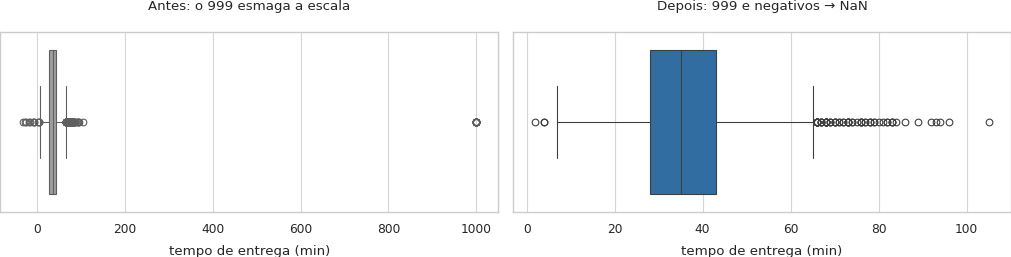

In [17]:
invalido = (df["tempo_entrega_min"] == 999) | (df["tempo_entrega_min"] < 0)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
sns.boxplot(x=df["tempo_entrega_min"], ax=axes[0], color="#9e9e9e")
axes[0].set_title("Antes: o 999 esmaga a escala"); axes[0].set_xlabel("tempo de entrega (min)")
df["tempo_invalido"] = invalido
df.loc[invalido, "tempo_entrega_min"] = np.nan
sns.boxplot(x=df["tempo_entrega_min"], ax=axes[1], color="#1f6fb2")
axes[1].set_title("Depois: 999 e negativos → NaN"); axes[1].set_xlabel("tempo de entrega (min)")
plt.tight_layout(); plt.show()
print(f"Interpretação: {invalido.sum()} tempos inválidos viraram NaN (flag tempo_invalido). Agora vai de "
      f"{num(df['tempo_entrega_min'].min(),0)} a {num(df['tempo_entrega_min'].max(),0)} min.")

O `999` não é entrega demorada: é o sistema dizendo "não sei". Negativo é impossível. O resto do pedido continua válido, então a linha fica.
### Tarefa 4.2 — Distância

In [18]:
d = df["distancia_km"]
z = (d - d.mean()) / d.std()
q1, q3 = d.quantile([.25, .75]); iqr = q3 - q1
print(f"z-score > 3: {(z.abs() > 3).sum()} | 1,5·IQR: {((d < q1-1.5*iqr) | (d > q3+1.5*iqr)).sum()}")
print("Maiores distâncias:", d.nlargest(10).round(1).tolist())
maiores = d.dropna().nlargest(100).values
saltos_d = [(maiores[i]/maiores[i+1], i) for i in range(len(maiores)-1) if maiores[i+1] >= q3+1.5*iqr]
razao, i_s = max(saltos_d)
LIMITE_KM = float(np.ceil(maiores[i_s+1])) if razao > 1.5 else 50.0
df["distancia_invalida"] = (d > LIMITE_KM) | (d <= 0)
df.loc[df["distancia_invalida"], "distancia_km"] = np.nan
print(f"\nInterpretação: z-score e IQR medem o que é RARO, não o que é IMPOSSÍVEL. O salto entre os maiores valores mostra a fronteira: "
      f"{df['distancia_invalida'].sum()} distâncias acima de {num(LIMITE_KM,0)} km viraram NaN (flag distancia_invalida). "
      f"Máximo agora: {num(df['distancia_km'].max())} km.")

z-score > 3: 7 | 1,5·IQR: 194
Maiores distâncias: [399.6, 391.9, 369.2, 300.2, 253.0, 163.2, 160.3, 24.4, 18.6, 18.3]

Interpretação: z-score e IQR medem o que é RARO, não o que é IMPOSSÍVEL. O salto entre os maiores valores mostra a fronteira: 7 distâncias acima de 25 km viraram NaN (flag distancia_invalida). Máximo agora: 24,4 km.


### Tarefa 4.3 — Valor do pedido: critérios automáticos

In [19]:
v = df["valor_pedido"]
q1, q3 = v.quantile([.25, .75])
df["_iqr_global"] = v > q3 + 1.5*(q3 - q1)
lims = df.groupby("tipo_cozinha")["valor_pedido"].quantile([.25, .75]).unstack()
lims["sup"] = lims[.75] + 1.5*(lims[.75] - lims[.25])
df["_iqr_cozinha"] = v > df["tipo_cozinha"].map(lims["sup"])
df["_z3"] = ((v - v.mean()) / v.std()).abs() > 3
comp = df.groupby("tipo_cozinha")[["_iqr_global", "_iqr_cozinha", "_z3"]].sum()
comp.columns = ["IQR base inteira", "IQR dentro da cozinha", "z-score > 3"]
display(comp)
print(f"Interpretação: o IQR global sinaliza {comp.iloc[:,0].sum()} pedidos, concentrados em {comp.iloc[:,0].idxmax()} — a cozinha "
      f"mais cara, não pedidos estranhos. Dentro da cozinha são {comp.iloc[:,1].sum()}. O z-score marca só {comp.iloc[:,2].sum()}: "
      "os extremos inflam o desvio que deveria detectá-los.")

Interpretação: o IQR global sinaliza 352 pedidos, concentrados em Japonesa — a cozinha mais cara, não pedidos estranhos. Dentro da cozinha são 214. O z-score marca só 31: os extremos inflam o desvio que deveria detectá-los.


,IQR base inteira,IQR dentro da cozinha,z-score > 3
tipo_cozinha,,,
Brasileira,6,38,5
Doces,3,18,2
Hambúrguer,19,43,4
Japonesa,246,24,12
Pizza,70,60,4
Saudável,8,31,4


### Tarefa 4.4 — Erro ou pedido corporativo?

In [20]:
df["_razao"] = df["valor_pedido"] / df.groupby("tipo_cozinha")["valor_pedido"].transform("median")
r = df["_razao"].sort_values(ascending=False).reset_index(drop=True)
# regra de negócio: um pedido de 5× a mediana da cozinha equivale a ~5 refeições — volume de grupo/empresa
CORTE = 5.0
df["pedido_grande"] = df["_razao"] >= CORTE
grandes = df[df["pedido_grande"]]
print("Maiores razões valor / mediana da cozinha:", r.head(30).round(1).tolist())
print("Corte: 5× a mediana da cozinha (≈ 5 refeições num pedido só)")
display(grandes[["data_hora", "cidade", "bairro", "tipo_cozinha", "valor_pedido", "distancia_km", "taxa_entrega", "tempo_entrega_min"]]
        .sort_values("valor_pedido", ascending=False).round(1))
print(f"Interpretação: {len(grandes)} pedidos acima do corte ({num(CORTE)}× a mediana da cozinha), de {brl(grandes['valor_pedido'].min(),0)} "
      f"a {brl(grandes['valor_pedido'].max(),0)}, em {grandes['cidade'].nunique()} cidades, {grandes['tipo_cozinha'].nunique()} cozinhas e "
      f"{grandes['data'].nunique()} datas, com distância, taxa e tempo normais. O bairro mais frequente é {grandes['bairro'].mode()[0]} "
      f"({(grandes['bairro'] == grandes['bairro'].mode()[0]).sum()} dos {len(grandes)}) — concentração que sugere um cliente corporativo recorrente. "
      "Erro de digitação não teria esse padrão coerente: são pedidos REAIS (ex.: empresas) → mantidos com a flag pedido_grande.")

Maiores razões valor / mediana da cozinha: [30.9, 20.4, 19.4, 17.4, 13.9, 13.2, 12.9, 12.8, 11.4, 10.1, 9.9, 9.2, 9.1, 8.7, 8.5, 8.4, 8.4, 8.1, 7.6, 7.1, 6.5, 6.4, 6.1, 5.8, 4.8, 4.3, 3.4, 3.2, 3.2, 3.1]
Corte: 5× a mediana da cozinha (≈ 5 refeições num pedido só)
Interpretação: 24 pedidos acima do corte (5,0× a mediana da cozinha), de R$ 234 a R$ 2.299, em 3 cidades, 6 cozinhas e 23 datas, com distância, taxa e tempo normais. O bairro mais frequente é Vila Mariana (8 dos 24) — concentração que sugere um cliente corporativo recorrente. Erro de digitação não teria esse padrão coerente: são pedidos REAIS (ex.: empresas) → mantidos com a flag pedido_grande.


,data_hora,cidade,bairro,tipo_cozinha,valor_pedido,distancia_km,taxa_entrega,tempo_entrega_min
6904,2024-11-17 11:07:00,Rio de Janeiro,Barra da Tijuca,Pizza,2299.1,2.0,6.8,25.0
3553,2024-06-24 19:48:00,São Paulo,Vila Mariana,Japonesa,2207.8,0.9,5.8,18.0
4023,2024-07-14 12:46:00,São Paulo,Vila Mariana,Pizza,1442.0,0.8,0.0,27.0
1035,2024-02-23 19:48:00,São Paulo,Santana,Japonesa,1394.7,2.4,7.1,39.0
5238,2024-09-03 21:14:00,Rio de Janeiro,Botafogo,Japonesa,1074.2,3.8,0.0,26.0
6787,2024-11-12 17:33:00,Rio de Janeiro,Méier,Hambúrguer,1071.8,2.6,7.3,24.0
491,2024-01-24 20:59:00,São Paulo,Vila Mariana,Pizza,1035.3,2.1,6.9,34.0
4542,2024-08-01 21:39:00,Belo Horizonte,Lourdes,Japonesa,765.0,0.9,5.8,16.0
1736,2024-03-27 14:45:00,Rio de Janeiro,Tijuca,Hambúrguer,700.9,11.9,15.7,59.0
4286,2024-07-23 21:21:00,Belo Horizonte,Pampulha,Japonesa,697.9,3.3,7.9,35.0


### Tarefa 4.5 — Impacto na média

In [21]:
imp = pd.DataFrame({
    "média (todos)": df.groupby("tipo_cozinha")["valor_pedido"].mean(),
    "média (sem grandes)": df[~df["pedido_grande"]].groupby("tipo_cozinha")["valor_pedido"].mean(),
    "mediana (todos)": df.groupby("tipo_cozinha")["valor_pedido"].median(),
    "mediana (sem grandes)": df[~df["pedido_grande"]].groupby("tipo_cozinha")["valor_pedido"].median()})
imp.loc["BASE TODA"] = [v.mean(), v[~df["pedido_grande"]].mean(), v.median(), v[~df["pedido_grande"]].median()]
display(imp.round(2))
print(f"Interpretação: os pedidos grandes mudam a média geral em {brl(imp.iloc[-1,0]-imp.iloc[-1,1])} e a mediana em só "
      f"{brl(imp.iloc[-1,2]-imp.iloc[-1,3])}. Ticket típico = MEDIANA; média só para faturamento.")
df = df.drop(columns=["_iqr_global", "_iqr_cozinha", "_z3"])

Interpretação: os pedidos grandes mudam a média geral em R$ 2,14 e a mediana em só R$ 0,11. Ticket típico = MEDIANA; média só para faturamento.


,média (todos),média (sem grandes),mediana (todos),mediana (sem grandes)
tipo_cozinha,,,,
Brasileira,51.17,50.04,47.82,47.76
Doces,41.79,40.64,38.42,38.40
Hambúrguer,67.65,66.25,61.67,61.61
Japonesa,120.37,115.38,107.97,107.73
Pizza,82.79,79.91,74.31,74.28
Saudável,58.77,57.45,53.74,53.47
BASE TODA,71.55,69.41,61.61,61.50


In [22]:
# ✅ Checkpoint dos outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999
assert df["distancia_km"].max() < 100
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns)
assert len(df) == 8058
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1 — Tabela de resumo

In [23]:
NUM = ["valor_pedido", "taxa_entrega", "distancia_km", "tempo_entrega_min", "avaliacao"]
resumo = df[NUM].describe().T
resumo["IQR"] = resumo["75%"] - resumo["25%"]
resumo["CV (%)"] = resumo["std"] / resumo["mean"] * 100
resumo["assimetria"] = df[NUM].skew()
resumo["moda"] = [df[c].mode().iloc[0] for c in NUM]
resumo.round(2)

,count,mean,std,min,25%,50%,75%,max,IQR,CV (%),assimetria,moda
valor_pedido,8058.0,71.55,60.26,11.03,45.22,61.61,85.12,2299.10,39.90,84.22,17.52,48.52
taxa_entrega,8058.0,7.27,3.29,0.00,6.16,7.42,9.08,26.94,2.92,45.20,-0.51,0.00
distancia_km,7736.0,3.54,2.39,0.08,1.77,3.02,4.76,24.39,2.99,67.55,1.37,2.70
tempo_entrega_min,8025.0,35.91,11.10,2.00,28.00,35.00,43.00,105.00,15.00,30.92,0.52,34.00
avaliacao,6716.0,4.35,0.69,1.00,4.00,4.00,5.00,5.00,1.00,15.76,-0.70,5.00


### Tarefa 5.2 — Interpretação

In [24]:
ma, mc = resumo["assimetria"].abs().idxmax(), resumo["CV (%)"].idxmax()
moda_taxa = resumo.loc["taxa_entrega", "moda"]
print(f"(a) Mais assimétrica: {ma} ({num(resumo.loc[ma,'assimetria'],2)}) — média {num(resumo.loc[ma,'mean'],2)} × mediana "
      f"{num(resumo.loc[ma,'50%'],2)} → usar mediana.")
print(f"(b) Maior variabilidade relativa: {mc} (CV {num(resumo.loc[mc,'CV (%)'])}%).")
print(f"(c) Moda da taxa: {brl(moda_taxa)} em {pct((df['taxa_entrega'] == moda_taxa).mean())} dos pedidos" +
      (" — frete grátis é o mais comum: política comercial, não custo típico." if moda_taxa == 0 else "."))
print(f"(d) Avaliação média {num(resumo.loc['avaliacao','mean'],2)}, mas só {pct(df['avaliacao'].notna().mean())} dos pedidos foram avaliados.")

(a) Mais assimétrica: valor_pedido (17,52) — média 71,55 × mediana 61,61 → usar mediana.
(b) Maior variabilidade relativa: valor_pedido (CV 84,2%).
(c) Moda da taxa: R$ 0,00 em 11,2% dos pedidos — frete grátis é o mais comum: política comercial, não custo típico.
(d) Avaliação média 4,35, mas só 83,3% dos pedidos foram avaliados.


### Tarefa 5.3 — Categóricas

In [25]:
for col in ["cidade", "tipo_cozinha", "forma_pagamento", "plataforma"]:
    dist = df[col].value_counts(normalize=True)
    print(f"{col}: moda = {dist.index[0]} | " + " · ".join(f"{k} {pct(x)}" for k, x in dist.items()))

cidade: moda = São Paulo | São Paulo 50,3% · Rio de Janeiro 29,4% · Belo Horizonte 20,3%
tipo_cozinha: moda = Hambúrguer | Hambúrguer 23,8% · Pizza 22,2% · Brasileira 19,4% · Japonesa 13,8% · Saudável 10,7% · Doces 10,1%
forma_pagamento: moda = Cartão de crédito | Cartão de crédito 45,2% · Pix 32,7% · Vale-refeição 15,2% · Dinheiro 7,0%
plataforma: moda = Android | Android 55,2% · iOS 31,9% · Web 10,9% · Não informada 1,8% ·  0,1%


### Tarefa 5.4 — Métrica operacional

In [26]:
t = df["tempo_entrega_min"].dropna()
perc = t.quantile([.5, .75, .9, .95])
acima45 = (t > 45).mean()
display(perc.rename(lambda q: f"P{int(q*100)}").round(1).to_frame("minutos"))
print(f"Interpretação: metade das entregas leva até {num(perc[.5],0)} min e 90% até {num(perc[.9],0)} min. {pct((t > 35).mean())} passam "
      f"de 35 min e {pct(acima45)} de 45 min — {num((t > 45).sum(),0)} pedidos quebrariam a promessa de 45 min.")

Interpretação: metade das entregas leva até 35 min e 90% até 50 min. 48,7% passam de 35 min e 18,4% de 45 min — 1.476 pedidos quebrariam a promessa de 45 min.


,minutos
P50,35.0
P75,43.0
P90,50.0
P95,55.0


---
## Etapa 6 — Sumarização e granularidade

### Tarefa 6.1 — Painel de KPIs

In [27]:
pd.Series({
    "pedidos": len(df), "faturamento em itens (R$)": df["valor_pedido"].sum(),
    "receita de taxa (R$)": df["taxa_entrega"].sum(), "ticket médio (R$)": df["valor_pedido"].mean(),
    "ticket mediano (R$)": df["valor_pedido"].median(), "% com cupom": df["cupom"].mean()*100,
    "% clientes novos": df["cliente_novo"].mean()*100, "% frete grátis": (df["taxa_entrega"] == 0).mean()*100,
    "tempo médio (min)": df["tempo_entrega_min"].mean(), "% acima de 45 min": acima45*100,
    "avaliação média": df["avaliacao"].mean(), "% avaliados": df["avaliacao"].notna().mean()*100,
}).round(2).to_frame("2024")

,2024
pedidos,8058.00
faturamento em itens (R$),576584.75
receita de taxa (R$),58571.40
ticket médio (R$),71.55
ticket mediano (R$),61.61
% com cupom,21.21
% clientes novos,17.37
% frete grátis,11.17
tempo médio (min),35.91
% acima de 45 min,18.39


### Tarefa 6.2 — Por cidade

In [28]:
chuva_cd = df.groupby(["cidade", "data"])["chuva"].first()
por_cidade = (df.groupby("cidade").agg(pedidos=("pedido_id", "size"), faturamento=("valor_pedido", "sum"),
                                       ticket_mediano=("valor_pedido", "median"), tempo_medio=("tempo_entrega_min", "mean"),
                                       avaliacao_media=("avaliacao", "mean"), pct_cupom=("cupom", "mean"))
              .assign(participacao=lambda x: x["pedidos"]/x["pedidos"].sum()*100, pct_cupom=lambda x: x["pct_cupom"]*100,
                      pct_dias_chuva=chuva_cd.groupby("cidade").mean()*100).sort_values("pedidos", ascending=False))
display(por_cidade.round(2))
print(f"Interpretação: {por_cidade.index[0]} lidera com {num(por_cidade['participacao'].iloc[0])}% dos pedidos; maior tempo médio em "
      f"{por_cidade['tempo_medio'].idxmax()} ({num(por_cidade['tempo_medio'].max())} min). % de dias com chuva calculado por CIDADE-DIA.")

Interpretação: São Paulo lidera com 50,3% dos pedidos; maior tempo médio em Belo Horizonte (36,3 min). % de dias com chuva calculado por CIDADE-DIA.


,pedidos,faturamento,ticket_mediano,tempo_medio,avaliacao_media,pct_cupom,participacao,pct_dias_chuva
cidade,,,,,,,,
São Paulo,4055,289275.55,61.54,35.86,4.35,21.60,50.32,25.21
Rio de Janeiro,2371,172029.24,61.43,35.71,4.36,20.75,29.42,24.45
Belo Horizonte,1632,115279.96,62.04,36.34,4.34,20.89,20.25,26.39


### Tarefa 6.3 — Por cozinha

In [29]:
por_cozinha = (df.groupby("tipo_cozinha").agg(pedidos=("pedido_id", "size"), ticket_medio=("valor_pedido", "mean"),
                                              ticket_mediano=("valor_pedido", "median"), faturamento=("valor_pedido", "sum"))
               .assign(part_faturamento=lambda x: x["faturamento"]/x["faturamento"].sum()*100).sort_values("ticket_mediano", ascending=False))
display(por_cozinha.round(2))
ov, of = por_cozinha["pedidos"].sort_values(ascending=False).index.tolist(), por_cozinha["faturamento"].sort_values(ascending=False).index.tolist()
print(f"Interpretação: maior ticket mediano {por_cozinha.index[0]} ({brl(por_cozinha['ticket_mediano'].iloc[0])}), menor "
      f"{por_cozinha.index[-1]} ({brl(por_cozinha['ticket_mediano'].iloc[-1])}). Por volume: {', '.join(ov)}. Por faturamento: {', '.join(of)}. "
      + ("Mesma ordem." if ov == of else "Ordens DIFERENTES: vender mais não é faturar mais."))

Interpretação: maior ticket mediano Japonesa (R$ 107,97), menor Doces (R$ 38,42). Por volume: Hambúrguer, Pizza, Brasileira, Japonesa, Saudável, Doces. Por faturamento: Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces. Ordens DIFERENTES: vender mais não é faturar mais.


,pedidos,ticket_medio,ticket_mediano,faturamento,part_faturamento
tipo_cozinha,,,,,
Japonesa,1116,120.37,107.97,134328.26,23.30
Pizza,1786,82.79,74.31,147857.26,25.64
Hambúrguer,1921,67.65,61.67,129963.40,22.54
Saudável,860,58.77,53.74,50544.31,8.77
Brasileira,1561,51.17,47.82,79871.60,13.85
Doces,814,41.79,38.42,34019.92,5.90


### Tarefa 6.4 — Plataforma e pagamento

In [30]:
display(df.groupby("plataforma").agg(pedidos=("pedido_id", "size"), ticket_mediano=("valor_pedido", "median"),
                                     avaliacao_media=("avaliacao", "mean")).round(2))
cross_pag = pd.crosstab(df["cidade"], df["forma_pagamento"], normalize="index").mul(100).round(1)
display(cross_pag)
amp = (cross_pag.max() - cross_pag.min()).sort_values(ascending=False)
print(f"Interpretação: a forma que mais varia entre cidades é {amp.index[0]} ({num(amp.iloc[0])} p.p.). Testado na H5.")

Interpretação: a forma que mais varia entre cidades é Cartão de crédito (1,7 p.p.). Testado na H5.


,pedidos,ticket_mediano,avaliacao_media
plataforma,,,
,11,63.48,4.50
Android,4449,61.67,4.35
Não informada,142,62.26,4.38
Web,882,62.96,4.33
iOS,2574,60.76,4.35


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.3,6.9,32.6,14.3
Rio de Janeiro,45.5,6.9,33.1,14.6
São Paulo,44.6,7.1,32.5,15.9


### Tarefa 6.5 — Três granularidades de tempo

Dia anômalo: 14/08/2024 com 1 pedido(s) (mediana diária 22) — compatível com instabilidade do app.
Semanas incompletas: 05/01 (2 dias)
Interpretação: o DIA mostra eventos pontuais; a SEMANA mostra tendência (as incompletas parecem quedas falsas); o MÊS mostra sazonalidade, mas meses têm tamanhos diferentes → comparar MÉDIA POR DIA.


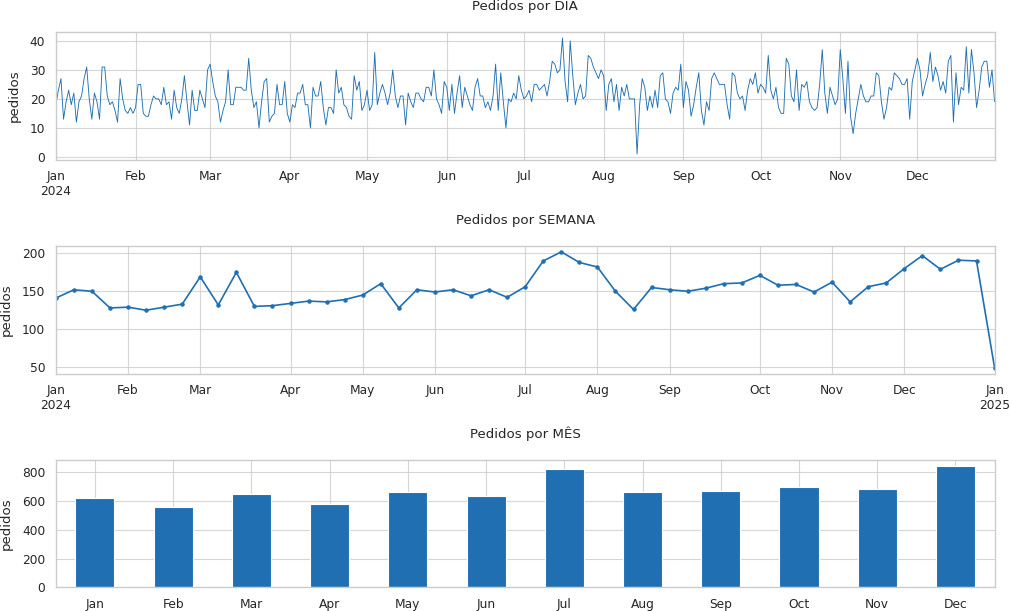

In [31]:
diaria = df.groupby("data").size().asfreq("D", fill_value=0)
semanal = df.set_index("data_hora").resample("W-SUN").size()
dias_sem = df.set_index("data_hora").resample("W-SUN")["data"].nunique()
mensal = df.set_index("data_hora").resample("MS").size()
zdia = (diaria - diaria.rolling(15, center=True, min_periods=5).median()) / diaria.std()
DIA_ANOMALO = zdia.idxmin()
fig, axes = plt.subplots(3, 1, figsize=(13, 8))
diaria.plot(ax=axes[0], color="#1f6fb2", lw=.8); axes[0].set_title("Pedidos por DIA")
semanal.plot(ax=axes[1], color="#1f6fb2", marker="o", ms=3); axes[1].set_title("Pedidos por SEMANA")
mensal.plot(ax=axes[2], kind="bar", color="#1f6fb2"); axes[2].set_title("Pedidos por MÊS")
axes[2].set_xticklabels([x.strftime("%b") for x in mensal.index], rotation=0)
for ax in axes: ax.set_xlabel(""); ax.set_ylabel("pedidos")
plt.tight_layout(); plt.show()
print(f"Dia anômalo: {DIA_ANOMALO:%d/%m/%Y} com {diaria[DIA_ANOMALO]} pedido(s) (mediana diária {num(diaria.median(),0)}) — compatível com instabilidade do app.")
print("Semanas incompletas: " + ", ".join(f"{x:%d/%m} ({n} dias)" for x, n in dias_sem[dias_sem < 7].items()))
print("Interpretação: o DIA mostra eventos pontuais; a SEMANA mostra tendência (as incompletas parecem quedas falsas); "
      "o MÊS mostra sazonalidade, mas meses têm tamanhos diferentes → comparar MÉDIA POR DIA.")

### Tarefa 6.6 — Hora × dia da semana

In [32]:
pivo = df.pivot_table(index="hora", columns="dia_semana", values="pedido_id", aggfunc="count", fill_value=0, observed=False)
cal = pd.Series(pd.date_range(df["data"].min(), df["data"].max(), freq="D"))
n_dias = cal.dt.dayofweek.map(dict(enumerate(DIAS))).value_counts().reindex(DIAS)
media_dia = (df.groupby("dia_semana", observed=False).size() / n_dias).round(1)
display(pd.DataFrame({"total": df["dia_semana"].value_counts().reindex(DIAS), "nº de dias": n_dias, "média por dia": media_dia}))
pico_h = pivo.sum(axis=1).idxmax()
print(f"Interpretação: pico às {pico_h}h; dia mais forte em média: {media_dia.idxmax()} ({num(media_dia.max())}/dia), mais fraco "
      f"{media_dia.idxmin()} ({num(media_dia.min())}/dia). A média por dia é mais justa porque o ano não tem o mesmo número de cada dia da semana.")

Interpretação: pico às 20h; dia mais forte em média: Sex (26,5/dia), mais fraco Qua (19,6/dia). A média por dia é mais justa porque o ano não tem o mesmo número de cada dia da semana.


,total,nº de dias,média por dia
Seg,1107,53,20.9
Ter,1064,53,20.1
Qua,1020,52,19.6
Qui,1049,52,20.2
Sex,1379,52,26.5
Sáb,1365,52,26.2
Dom,1074,52,20.7


### Tarefa 6.7 — Cupom

In [33]:
comp_cupom = df.groupby("cupom").agg(pedidos=("pedido_id", "size"), ticket_mediano=("valor_pedido", "median"),
                                     pct_cliente_novo=("cliente_novo", "mean"), avaliacao_media=("avaliacao", "mean"))
comp_cupom["pct_cliente_novo"] *= 100
display(comp_cupom.rename(index={True: "com cupom", False: "sem cupom"}).round(2))
por_mes = pd.DataFrame({"taxa_cupom_%": df.groupby("mes")["cupom"].mean()*100,
                        "pedidos_por_dia": df.groupby("mes").size() / df.groupby("mes")["data"].nunique()})
display(por_mes.round(1))
jul, resto = por_mes.loc[7], por_mes.drop(7).mean()
var_jul = (jul["pedidos_por_dia"]/resto["pedidos_por_dia"] - 1)*100
print(f"Interpretação: com cupom {num(comp_cupom.loc[True,'pct_cliente_novo'])}% são clientes novos, sem cupom "
      f"{num(comp_cupom.loc[False,'pct_cliente_novo'])}%. Em julho o uso de cupom foi {num(jul['taxa_cupom_%'])}% (outros meses "
      f"{num(resto['taxa_cupom_%'])}%) e os pedidos/dia variaram {num(var_jul)}% em relação à média dos outros meses.")

Interpretação: com cupom 34,3% são clientes novos, sem cupom 12,8%. Em julho o uso de cupom foi 45,6% (outros meses 18,5%) e os pedidos/dia variaram 22,9% em relação à média dos outros meses.


,pedidos,ticket_mediano,pct_cliente_novo,avaliacao_media
cupom,,,,
sem cupom,6349,62.82,12.81,4.36
com cupom,1709,57.22,34.35,4.31


,taxa_cupom_%,pedidos_por_dia
mes,,
1,16.2,19.9
2,23.6,19.3
3,19.9,20.9
4,16.6,19.3
5,18.6,21.3
6,19.5,21.0
7,45.6,26.5
8,21.1,21.4
9,18.8,22.1


### Tarefa 6.8 — Chuva: a granularidade certa

In [34]:
tc = df.groupby("chuva")["tempo_entrega_min"].mean()
print(f"(a) Tempo médio: sem chuva {num(tc[False])} min | com chuva {num(tc[True])} min.")
cd = df.groupby(["cidade", "data"]).agg(pedidos=("pedido_id", "size"), chuva=("chuva", "first")).reset_index()
pcd = cd.pivot_table(index="cidade", columns="chuva", values="pedidos", aggfunc="mean").rename(columns={False: "sem chuva", True: "com chuva"})
pcd["variação %"] = (pcd["com chuva"]/pcd["sem chuva"] - 1)*100
display(pcd.round(1))
print(f"(b) Por cidade-dia, a chuva muda os pedidos em {num(pcd['variação %'].min())}% a {num(pcd['variação %'].max())}%. Comparar o TOTAL "
      "não serve: há muito mais dias secos. A unidade certa é o cidade-dia.")

(a) Tempo médio: sem chuva 33,2 min | com chuva 42,4 min.
(b) Por cidade-dia, a chuva muda os pedidos em 16,0% a 27,1%. Comparar o TOTAL não serve: há muito mais dias secos. A unidade certa é o cidade-dia.


chuva,sem chuva,com chuva,variação %
cidade,,,
Belo Horizonte,4.3,5.3,24.6
Rio de Janeiro,6.3,7.3,16.0
São Paulo,10.4,13.2,27.1


### Tarefa 6.9 — Crescimento

In [35]:
tri = diaria.groupby(diaria.index.quarter).mean()
serie = diaria.drop(DIA_ANOMALO)
x = (serie.index - serie.index[0]).days.values
a, b = np.polyfit(x, serie.values, 1)
print(f"(a) Pedidos/dia: 1º tri {num(tri.iloc[0])} → 4º tri {num(tri.iloc[-1])} ({num((tri.iloc[-1]/tri.iloc[0]-1)*100)}%).")
print(f"(b) Reta ajustada (sem o dia anômalo): de {num(b)} a {num(a*x.max()+b)} pedidos/dia no ano ({num(((a*x.max()+b)/b-1)*100)}%).")

(a) Pedidos/dia: 1º tri 20,0 → 4º tri 24,1 (20,2%).
(b) Reta ajustada (sem o dia anômalo): de 19,1 a 25,0 pedidos/dia no ano (31,1%).


---
## Etapa 7 — Visualizações

### Tarefa 7.0 — Padrão visual

In [36]:
COR = {"destaque": "#1f6fb2", "neutro": "#b8b8b8", "alerta": "#d1495b", "chuva": "#3a6ea5", "seco": "#e0a458"}
fmt_reais = mticker.FuncFormatter(lambda x, _: f"R$ {x:,.0f}".replace(",", "."))
fmt_pct = mticker.FuncFormatter(lambda x, _: f"{x:.0f}%")
def titulo(ax, texto, sub=None):
    ax.set_title(texto, loc="left", fontsize=13, fontweight="bold", pad=22 if sub else 8)
    if sub: ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=10, color="#555555")
def limpa(ax, grade="y"):
    sns.despine(ax=ax, left=(grade == "x")); ax.grid(axis="x" if grade == "y" else "y", visible=False)
print("Padrão: azul = principal, cinza = contexto, vermelho = alerta; chuva azul-escuro, seco laranja.")

Padrão: azul = principal, cinza = contexto, vermelho = alerta; chuva azul-escuro, seco laranja.


### Tarefa 7.1 — Distribuição do ticket

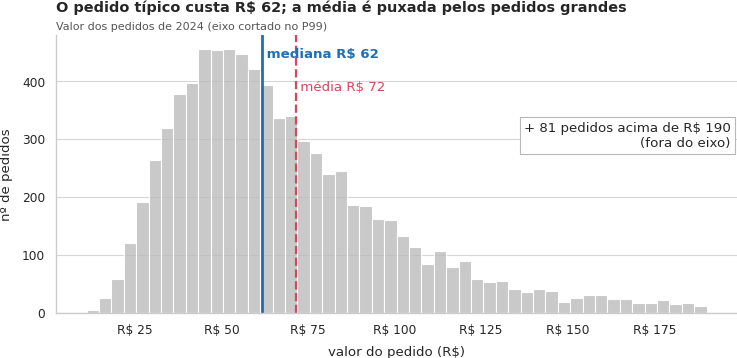

In [37]:
CE = df["valor_pedido"].quantile(.99)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.histplot(df.loc[df["valor_pedido"] <= CE, "valor_pedido"], bins=50, color=COR["neutro"], ax=ax)
med, media = df["valor_pedido"].median(), df["valor_pedido"].mean()
ax.axvline(med, color=COR["destaque"], lw=2.5); ax.axvline(media, color=COR["alerta"], lw=2, ls="--")
ax.text(med, ax.get_ylim()[1]*.92, f" mediana {brl(med,0)}", color=COR["destaque"], fontweight="bold")
ax.text(media, ax.get_ylim()[1]*.80, f" média {brl(media,0)}", color=COR["alerta"])
ax.text(.99, .6, f"+ {(df['valor_pedido'] > CE).sum()} pedidos acima de {brl(CE,0)}\n(fora do eixo)", transform=ax.transAxes, ha="right",
        bbox=dict(fc="white", ec=COR["neutro"]))
ax.xaxis.set_major_formatter(fmt_reais); ax.set_xlabel("valor do pedido (R$)"); ax.set_ylabel("nº de pedidos")
titulo(ax, f"O pedido típico custa {brl(med,0)}; a média é puxada pelos pedidos grandes", "Valor dos pedidos de 2024 (eixo cortado no P99)")
limpa(ax); plt.show()

**Leitura:** a maioria dos pedidos fica perto da mediana; a cauda à direita (pedidos de empresas) puxa a média para cima.
### Tarefa 7.2 — Participação por cidade

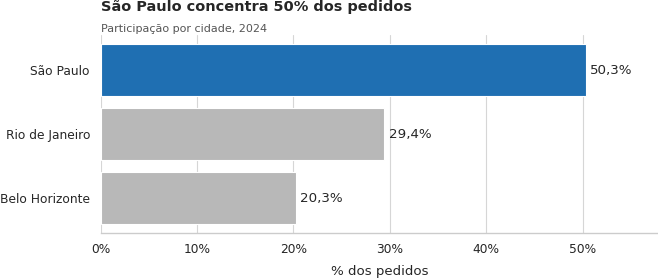

In [38]:
part = df["cidade"].value_counts(normalize=True).mul(100).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.2))
bb = ax.barh(part.index, part.values, color=[COR["destaque"] if c == part.idxmax() else COR["neutro"] for c in part.index])
ax.bar_label(bb, labels=[num(x) + "%" for x in part.values], padding=4)
ax.xaxis.set_major_formatter(fmt_pct); ax.set_xlabel("% dos pedidos"); ax.set_xlim(0, part.max()*1.15)
titulo(ax, f"{part.idxmax()} concentra {num(part.max(),0)}% dos pedidos", "Participação por cidade, 2024")
limpa(ax, "x"); plt.show()

**Leitura:** metade da operação está em São Paulo; qualquer plano operacional começa por lá.
### Tarefa 7.3 — Ticket por cozinha

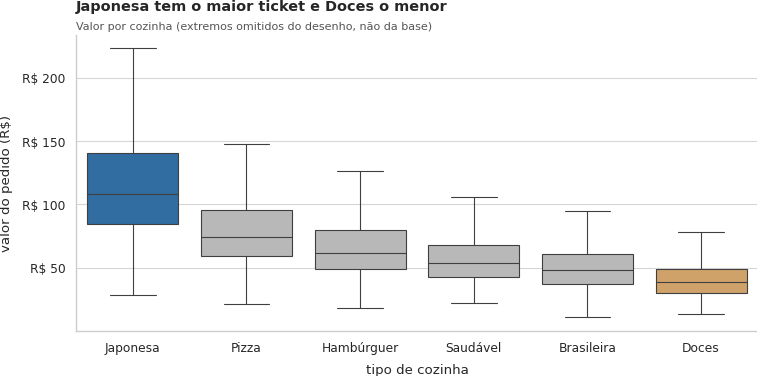

In [39]:
ordem = df.groupby("tipo_cozinha")["valor_pedido"].median().sort_values(ascending=False).index
cores = {c: COR["neutro"] for c in ordem}; cores[ordem[0]] = COR["destaque"]; cores[ordem[-1]] = COR["seco"]
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.boxplot(data=df, x="tipo_cozinha", y="valor_pedido", order=ordem, hue="tipo_cozinha", palette=cores, legend=False, showfliers=False, ax=ax)
ax.yaxis.set_major_formatter(fmt_reais); ax.set_xlabel("tipo de cozinha"); ax.set_ylabel("valor do pedido (R$)")
titulo(ax, f"{ordem[0]} tem o maior ticket e {ordem[-1]} o menor", "Valor por cozinha (extremos omitidos do desenho, não da base)")
limpa(ax); plt.show()

**Leitura:** as caixas quase não se sobrepõem entre Japonesa e Doces — a cozinha define o ticket.
### Tarefa 7.4 — Evolução diária

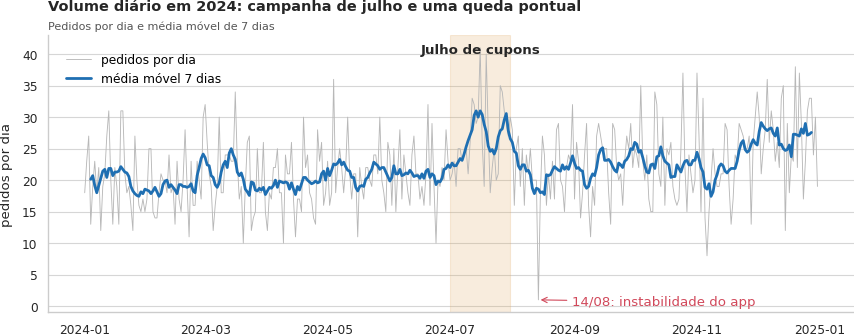

In [40]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(diaria.index, diaria.values, color=COR["neutro"], lw=.8, label="pedidos por dia")
ax.plot(diaria.index, diaria.rolling(7, center=True).mean(), color=COR["destaque"], lw=2.5, label="média móvel 7 dias")
ax.axvspan(pd.Timestamp("2024-07-01"), pd.Timestamp("2024-07-31"), color=COR["seco"], alpha=.2)
ax.text(pd.Timestamp("2024-07-16"), ax.get_ylim()[1]*.97, "Julho de cupons", ha="center", va="top", fontweight="bold")
ax.annotate(f"{DIA_ANOMALO:%d/%m}: instabilidade do app", xy=(DIA_ANOMALO, diaria[DIA_ANOMALO]), xytext=(30, -5),
            textcoords="offset points", color=COR["alerta"], arrowprops=dict(arrowstyle="->", color=COR["alerta"]))
ax.set_ylabel("pedidos por dia"); ax.legend(loc="upper left", frameon=False)
titulo(ax, "Volume diário em 2024: campanha de julho e uma queda pontual", "Pedidos por dia e média móvel de 7 dias")
limpa(ax); plt.show()

**Leitura:** julho se destaca pela campanha; a queda isolada de agosto é um evento técnico, não tendência.
### Tarefa 7.5 — Quando os pedidos acontecem

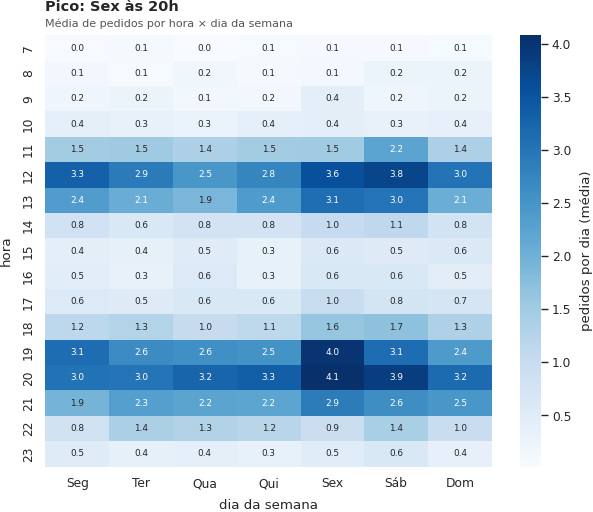

In [41]:
media_hd = pivo / n_dias.values
media_hd = media_hd.loc[media_hd.sum(axis=1) > 0]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(media_hd, cmap="Blues", annot=True, fmt=".1f", annot_kws={"size": 8}, cbar_kws={"label": "pedidos por dia (média)"}, ax=ax)
h, d_ = np.unravel_index(media_hd.values.argmax(), media_hd.shape)
ax.set_xlabel("dia da semana"); ax.set_ylabel("hora")
titulo(ax, f"Pico: {media_hd.columns[d_]} às {media_hd.index[h]}h", "Média de pedidos por hora × dia da semana")
plt.show()

**Leitura:** dois picos por dia (almoço e jantar), mais fortes no fim de semana.
### Tarefa 7.6 — Chuva e tempo de entrega

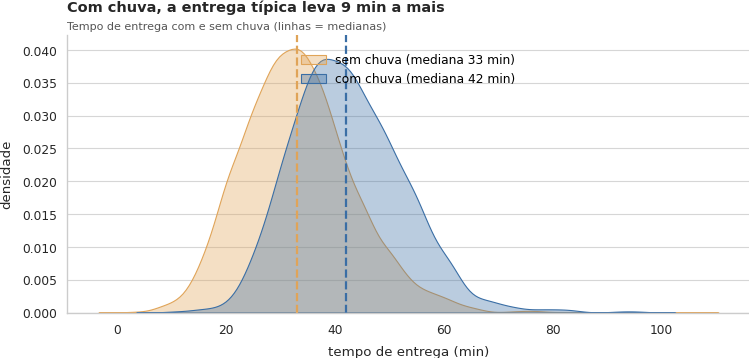

In [42]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for flag, cor, rot in [(False, COR["seco"], "sem chuva"), (True, COR["chuva"], "com chuva")]:
    s = df.loc[df["chuva"] == flag, "tempo_entrega_min"].dropna()
    sns.kdeplot(s, fill=True, alpha=.35, color=cor, ax=ax, label=f"{rot} (mediana {s.median():.0f} min)")
    ax.axvline(s.median(), color=cor, lw=2, ls="--")
dif = df[df.chuva].tempo_entrega_min.median() - df[~df.chuva].tempo_entrega_min.median()
ax.set_xlabel("tempo de entrega (min)"); ax.set_ylabel("densidade"); ax.legend(frameon=False)
titulo(ax, f"Com chuva, a entrega típica leva {num(dif,0)} min a mais", "Tempo de entrega com e sem chuva (linhas = medianas)")
limpa(ax); plt.show()

**Leitura:** a curva inteira se desloca para a direita com chuva — não são só alguns casos.
### Tarefa 7.7 — Tempo × avaliação

,mean,size
faixa_tempo,,
10–15,4.44,70
15–20,4.52,284
20–25,4.49,622
25–30,4.48,943
30–35,4.49,1248
35–40,4.44,1185
40–45,4.29,913
45–50,4.15,621
50–55,4.05,410


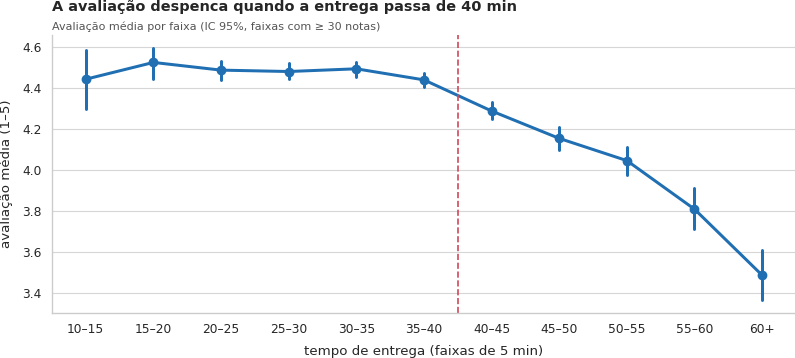

In [43]:
rot = [f"{i}–{i+5}" for i in range(0, 60, 5)] + ["60+"]
df["faixa_tempo"] = pd.cut(df["tempo_entrega_min"], list(range(0, 61, 5)) + [np.inf], labels=rot, right=False)
aval_faixa = df.dropna(subset=["avaliacao", "faixa_tempo"])
mf = aval_faixa.groupby("faixa_tempo", observed=True)["avaliacao"].agg(["mean", "size"])
mf = mf[mf["size"] >= 30]
qq = mf.index[(mf["mean"] < mf["mean"].max() - .2) & (np.arange(len(mf)) > mf["mean"].values.argmax())]
FAIXA_QUEDA = qq[0] if len(qq) else mf.index[-1]
pos = list(mf.index).index(FAIXA_QUEDA)
display(mf.round(2))
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.pointplot(data=aval_faixa[aval_faixa["faixa_tempo"].isin(mf.index)], x="faixa_tempo", y="avaliacao", order=mf.index,
              errorbar=("ci", 95), color=COR["destaque"], ax=ax)
ax.axvline(pos - .5, color=COR["alerta"], ls="--")
ax.set_xlabel("tempo de entrega (faixas de 5 min)"); ax.set_ylabel("avaliação média (1–5)")
titulo(ax, f"A avaliação despenca quando a entrega passa de {FAIXA_QUEDA.split('–')[0]} min", "Avaliação média por faixa (IC 95%, faixas com ≥ 30 notas)")
limpa(ax); plt.show()

**Leitura:** a nota fica estável até perto de 40 min e cai rápido depois — há um ponto de virada, não uma queda contínua.
### Tarefa 7.8 — O efeito do cupom

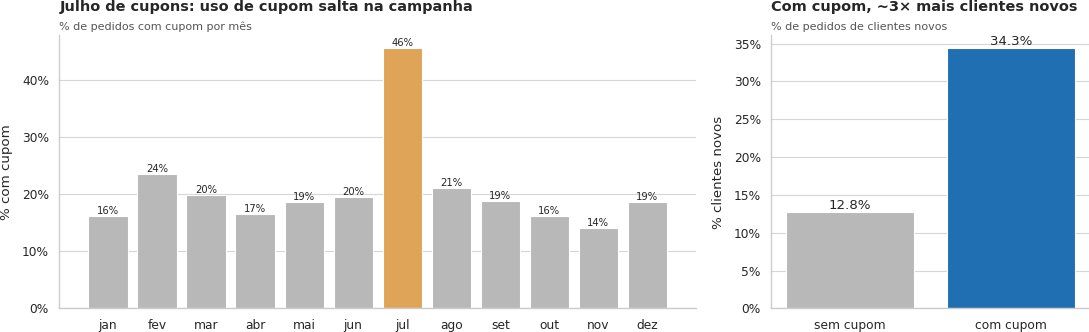

In [44]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
tm = por_mes["taxa_cupom_%"]
b1 = a1.bar(tm.index, tm.values, color=[COR["seco"] if m == 7 else COR["neutro"] for m in tm.index])
a1.bar_label(b1, labels=[f"{x:.0f}%" for x in tm.values], fontsize=9)
a1.set_xticks(range(1, 13)); a1.set_xticklabels(["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"])
a1.yaxis.set_major_formatter(fmt_pct); a1.set_ylabel("% com cupom")
titulo(a1, "Julho de cupons: uso de cupom salta na campanha", "% de pedidos com cupom por mês")
nv = comp_cupom["pct_cliente_novo"].rename({False: "sem cupom", True: "com cupom"})
b2 = a2.bar(nv.index, nv.values, color=[COR["neutro"], COR["destaque"]])
a2.bar_label(b2, labels=[f"{x:.1f}%" for x in nv.values])
a2.yaxis.set_major_formatter(fmt_pct); a2.set_ylabel("% clientes novos")
titulo(a2, "Com cupom, ~3× mais clientes novos", "% de pedidos de clientes novos")
limpa(a1); limpa(a2); plt.tight_layout(); plt.show()

**Leitura:** o uso de cupom fica perto de 18% no ano e salta em julho; quem usa cupom é muito mais frequentemente cliente novo.
### Tarefa 7.9 — Por que cada gráfico
| Gráfico | Por que |
|---|---|
| 7.1 Histograma | mostra a assimetria e marca média × mediana |
| 7.2 Barras horizontais | comparar participação de poucas categorias com rótulo |
| 7.3 Boxplot | comparar distribuições entre grupos |
| 7.4 Linha + média móvel | evolução no tempo, sem ruído do dia da semana |
| 7.5 Heatmap | cruzar duas dimensões (hora × dia) |
| 7.6 Densidades | deslocamento da distribuição inteira |
| 7.7 Pontos com IC | média por faixa com incerteza visível |
| 7.8 Dois painéis | quando o cupom foi usado e quem ele atraiu |

---
## Etapa 8 — Correlação

### Tarefa 8.1 — Pearson × Spearman

Mais fortes: taxa_entrega × distancia_km (0,79); tempo_entrega_min × distancia_km (0,65); taxa_entrega × tempo_entrega_min (0,52)
Interpretação: uso Spearman como referência porque a nota é ordinal e há caudas longas; Pearson mede só relação linear e é sensível a extremos.


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.00,0.70,0.58,-0.01,-0.23
tempo_entrega_min,0.70,1.00,0.42,-0.01,-0.29
taxa_entrega,0.58,0.42,1.00,0.01,-0.10
valor_pedido,-0.01,-0.01,0.01,1.00,-0.01
avaliacao,-0.23,-0.29,-0.10,-0.01,1.00


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.00,0.65,0.79,-0.02,-0.17
tempo_entrega_min,0.65,1.00,0.52,-0.01,-0.24
taxa_entrega,0.79,0.52,1.00,0.01,-0.11
valor_pedido,-0.02,-0.01,0.01,1.00,0.01
avaliacao,-0.17,-0.24,-0.11,0.01,1.00


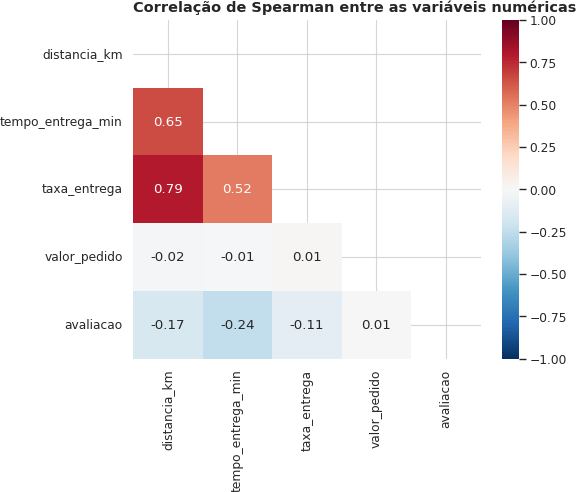

In [45]:
VARS = ["distancia_km", "tempo_entrega_min", "taxa_entrega", "valor_pedido", "avaliacao"]
sp = df[VARS].corr("spearman")
display(df[VARS].corr("pearson").round(2)); display(sp.round(2))
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(sp, mask=np.triu(np.ones_like(sp, dtype=bool)), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
titulo(ax, "Correlação de Spearman entre as variáveis numéricas")
plt.show()
pares = sp.where(np.tril(np.ones_like(sp, dtype=bool), -1)).stack().sort_values(key=abs, ascending=False)
print("Mais fortes: " + "; ".join(f"{a} × {b} ({num(r,2)})" for (a, b), r in pares.head(3).items()))
print("Interpretação: uso Spearman como referência porque a nota é ordinal e há caudas longas; Pearson mede só relação linear e é sensível a extremos.")

### Tarefa 8.2 — Distância × tempo, por chuva

sem chuva: tempo ≈ 22,1 + 3,20 min/km
com chuva: tempo ≈ 31,6 + 3,09 min/km
Interpretação: a chuva desloca a reta para cima (mais minutos para a mesma distância).


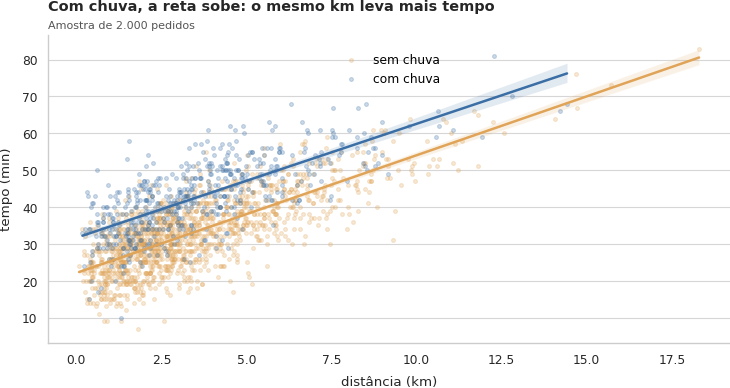

In [46]:
am = df.dropna(subset=["distancia_km", "tempo_entrega_min"]).sample(2000, random_state=42)
fig, ax = plt.subplots(figsize=(11, 5)); coef = {}
for flag, cor, rt in [(False, COR["seco"], "sem chuva"), (True, COR["chuva"], "com chuva")]:
    s = am[am["chuva"] == flag]
    sns.regplot(data=s, x="distancia_km", y="tempo_entrega_min", ax=ax, color=cor, scatter_kws={"alpha": .25, "s": 12}, label=rt)
    coef[rt] = np.polyfit(s["distancia_km"], s["tempo_entrega_min"], 1)
ax.set_xlabel("distância (km)"); ax.set_ylabel("tempo (min)"); ax.legend(frameon=False)
titulo(ax, "Com chuva, a reta sobe: o mesmo km leva mais tempo", "Amostra de 2.000 pedidos")
limpa(ax); plt.show()
for rt, (i_, c_) in coef.items(): print(f"{rt}: tempo ≈ {num(c_)} + {num(i_,2)} min/km")
print("Interpretação: a chuva desloca a reta para cima (mais minutos para a mesma distância).")

### Tarefa 8.3 — Taxa × distância: uma correlação "estranha"

Interpretação: Pearson com todos = 0,58; só taxa > 0 = 1,00. A taxa é CALCULADA pela distância (≈ R$ 4,99 + R$ 0,90/km), mas o frete grátis zera em qualquer distância e mistura duas populações.
Consequência para a limpeza: dos pedidos sem distância, 297 têm taxa > 0 — neles a distância poderia ser ESTIMADA pela taxa: distância ≈ (taxa − 4,99) / 0,90. Mantive NaN para não misturar dado medido com estimado, mas a imputação seria justificável.


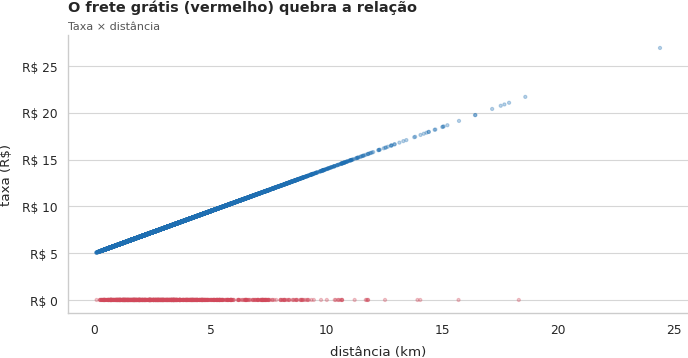

In [47]:
td = df.dropna(subset=["distancia_km"])
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(td["distancia_km"], td["taxa_entrega"], s=8, alpha=.3, c=np.where(td["taxa_entrega"] == 0, COR["alerta"], COR["destaque"]))
ax.yaxis.set_major_formatter(fmt_reais); ax.set_xlabel("distância (km)"); ax.set_ylabel("taxa (R$)")
titulo(ax, "O frete grátis (vermelho) quebra a relação", "Taxa × distância"); limpa(ax); plt.show()
pg = td[td["taxa_entrega"] > 0]
i_, c_ = np.polyfit(pg["distancia_km"], pg["taxa_entrega"], 1)
falt_dist = df["distancia_km"].isna() & (df["taxa_entrega"] > 0)
print(f"Interpretação: Pearson com todos = {num(td['distancia_km'].corr(td['taxa_entrega']),2)}; só taxa > 0 = "
      f"{num(pg['distancia_km'].corr(pg['taxa_entrega']),2)}. A taxa é CALCULADA pela distância (≈ {brl(c_)} + {brl(i_)}/km), "
      "mas o frete grátis zera em qualquer distância e mistura duas populações.")
print(f"Consequência para a limpeza: dos pedidos sem distância, {falt_dist.sum()} têm taxa > 0 — neles a distância poderia ser "
      f"ESTIMADA pela taxa: distância ≈ (taxa − {num(c_,2)}) / {num(i_,2)}. Mantive NaN para não misturar dado medido com estimado, "
      "mas a imputação seria justificável.")

### Tarefa 8.4 — Correlação não é causalidade
1. **Distância × tempo:** parte pode vir de **confundidores** — trânsito no pico e chuva aumentam o tempo.
2. **Cupom × cliente novo:** o app pode **dar cupom justamente para quem é novo** (cupom de boas-vindas). Só um teste A/B mediria o efeito causal.

---
## Etapa 9 — Testes de hipótese

In [48]:
ALFA = 0.05
resultados = []
def decide(p): return "rejeita H0" if p < ALFA else "não rejeita H0"
def fp(p): return "< 0,001" if p < .001 else num(p, 3)
def cramer(tb):
    return np.sqrt(stats.chi2_contingency(tb)[0] / (tb.values.sum()*(min(tb.shape)-1)))

### Tarefa 9.1 — H1: com chuva, a entrega demora mais?

In [49]:
com = df.loc[df["chuva"], "tempo_entrega_min"].dropna(); sem = df.loc[~df["chuva"], "tempo_entrega_min"].dropna()
u, p = stats.mannwhitneyu(com, sem, alternative="greater")
pw = stats.ttest_ind(com, sem, equal_var=False, alternative="greater").pvalue
ef_min = com.median() - sem.median()
resultados.append({"hipotese": "H1 chuva × tempo", "teste": "Mann-Whitney", "estatistica": u, "p_valor": p,
                   "efeito": f"+{num(ef_min,0)} min na mediana", "resposta": "SIM" if p < ALFA else "NÃO"})
print(f"U = {u:,.0f}, p {fp(p)} | Welch p {fp(pw)}. Medianas: com chuva {num(com.median())} × sem {num(sem.median())} min.")
print(f"Interpretação: {decide(p)} → SIM, com chuva a entrega típica leva {num(ef_min,0)} min a mais.")

U = 9,908,765, p < 0,001 | Welch p < 0,001. Medianas: com chuva 42,0 × sem 33,0 min.
Interpretação: rejeita H0 → SIM, com chuva a entrega típica leva 9 min a mais.


### Tarefa 9.2 — H2: o valor do pedido muda com cupom?

In [50]:
b2 = df[~df["pedido_grande"]]
c1, c0 = b2.loc[b2["cupom"], "valor_pedido"], b2.loc[~b2["cupom"], "valor_pedido"]
u, p = stats.mannwhitneyu(c1, c0)
pl = stats.ttest_ind(np.log(c1), np.log(c0), equal_var=False).pvalue
pb = stats.ttest_ind(df.loc[df.cupom, "valor_pedido"], df.loc[~df.cupom, "valor_pedido"], equal_var=False).pvalue
ef = c1.median() - c0.median()
resultados.append({"hipotese": "H2 cupom × valor", "teste": "Mann-Whitney", "estatistica": u, "p_valor": p,
                   "efeito": f"{brl(ef)} na mediana", "resposta": "SIM" if p < ALFA else "NÃO"})
print(f"U = {u:,.0f}, p {fp(p)} | Welch em log p {fp(pl)} | Welch bruto p {fp(pb)}.")
print(f"Interpretação: {decide(p)} → SIM. Mediana com cupom {brl(c1.median())} × sem {brl(c0.median())}.")

U = 4,726,534, p < 0,001 | Welch em log p < 0,001 | Welch bruto p 0,005.
Interpretação: rejeita H0 → SIM. Mediana com cupom R$ 57,10 × sem R$ 62,73.


O t de Welch no valor bruto é frágil: a média depende de quantos pedidos corporativos caíram em cada grupo. Por isso: Mann-Whitney sem os grandes, e t sobre o log como conferência.
### Tarefa 9.3 — H3: quanto mais demora, menor a nota?

In [51]:
h3 = df.dropna(subset=["tempo_entrega_min", "avaliacao"])
rho, p = stats.spearmanr(h3["tempo_entrega_min"], h3["avaliacao"])
rap, dem = h3.loc[h3.tempo_entrega_min <= 35, "avaliacao"], h3.loc[h3.tempo_entrega_min > 35, "avaliacao"]
resultados.append({"hipotese": "H3 tempo × nota", "teste": "Spearman", "estatistica": rho, "p_valor": p,
                   "efeito": f"nota {num(rap.mean(),2)} (≤35) × {num(dem.mean(),2)} (>35)", "resposta": "SIM" if (p < ALFA and rho < 0) else "NÃO"})
print(f"ρ = {num(rho,3)}, p {fp(p)}. Até 35 min nota {num(rap.mean(),2)}; acima {num(dem.mean(),2)}. Interpretação: {decide(p)} → SIM.")

ρ = -0,244, p < 0,001. Até 35 min nota 4,49; acima 4,20. Interpretação: rejeita H0 → SIM.


### Tarefa 9.4 — H4: o valor muda conforme a cozinha?

In [52]:
grupos = [g["valor_pedido"].values for _, g in b2.groupby("tipo_cozinha")]
H, p = stats.kruskal(*grupos); F, pa = stats.f_oneway(*grupos)
eps2 = (H - len(grupos) + 1) / (len(b2) - len(grupos))
med_c = b2.groupby("tipo_cozinha")["valor_pedido"].median().sort_values()
resultados.append({"hipotese": "H4 cozinha × valor", "teste": "Kruskal-Wallis", "estatistica": H, "p_valor": p,
                   "efeito": f"ε² = {num(eps2,2)}", "resposta": "SIM" if p < ALFA else "NÃO"})
print(f"H = {num(H)}, p {fp(p)} | ANOVA p {fp(pa)} | ε² = {num(eps2,3)}. Ticket de {brl(med_c.iloc[0])} ({med_c.index[0]}) a "
      f"{brl(med_c.iloc[-1])} ({med_c.index[-1]}). A cozinha explica cerca de {num(eps2*100,0)}% da variação do ticket → SIM.")

H = 3.303,3, p < 0,001 | ANOVA p < 0,001 | ε² = 0,411. Ticket de R$ 38,40 (Doces) a R$ 107,73 (Japonesa). A cozinha explica cerca de 41% da variação do ticket → SIM.


### Tarefa 9.5 — H5: a forma de pagamento muda por cidade? (+ contraste cupom × cliente novo)

In [53]:
tab = pd.crosstab(df["cidade"], df["forma_pagamento"])
chi2, p, gl, esp = stats.chi2_contingency(tab)
display(tab); display(pd.DataFrame(esp, index=tab.index, columns=tab.columns).round(1))
vc = cramer(tab)
resultados.append({"hipotese": "H5 cidade × pagamento", "teste": "qui-quadrado", "estatistica": chi2, "p_valor": p,
                   "efeito": f"V = {num(vc,2)}", "resposta": "SIM" if p < ALFA else "NÃO"})
print(f"cidade × pagamento: χ² = {num(chi2)}, p {fp(p)}, V = {num(vc,3)} → {decide(p)} → "
      + ("SIM." if p < ALFA else "NÃO: as três cidades pagam de forma parecida; o observado é quase igual ao esperado."))

# Contraste pedido pelo enunciado: o mesmo teste em cupom × cliente_novo
tab_c = pd.crosstab(df["cupom"], df["cliente_novo"])
chi2_c, p_c, _, _ = stats.chi2_contingency(tab_c)
v2 = cramer(tab_c)
p_novo = df.groupby("cupom")["cliente_novo"].mean()
print(f"\nContraste cupom × cliente_novo: χ² = {num(chi2_c)}, p {fp(p_c)}, V = {num(v2,3)}. "
      f"Com cupom {pct(p_novo[True])} são clientes novos; sem cupom {pct(p_novo[False])}.")
print(f"Interpretação do contraste: com 8 mil pedidos quase tudo dá p pequeno; o V é que mostra a força. "
      f"Pagamento × cidade tem V = {num(vc,2)} (nenhuma associação); cupom × cliente novo tem V = {num(v2,2)} (associação moderada) — "
      "é essa relação que aprofundo na H6.")

cidade × pagamento: χ² = 3,9, p 0,695, V = 0,015 → não rejeita H0 → NÃO: as três cidades pagam de forma parecida; o observado é quase igual ao esperado.

Contraste cupom × cliente_novo: χ² = 433,8, p < 0,001, V = 0,232. Com cupom 34,3% são clientes novos; sem cupom 12,8%.
Interpretação do contraste: com 8 mil pedidos quase tudo dá p pequeno; o V é que mostra a força. Pagamento × cidade tem V = 0,02 (nenhuma associação); cupom × cliente novo tem V = 0,23 (associação moderada) — é essa relação que aprofundo na H6.


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,755,112,532,233
Rio de Janeiro,1078,163,785,345
São Paulo,1809,286,1316,644


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,737.6,113.6,533.3,247.5
Rio de Janeiro,1071.6,165.1,774.7,359.6
São Paulo,1832.8,282.3,1325.0,614.9


### Tarefa 9.6 — H6 (minha): o cupom continua trazendo mais clientes novos mesmo fora do Julho de cupons?
**Variável confundidora controlada: a campanha de julho.** Em julho houve muito mais cupom e a campanha também pode ter atraído mais clientes novos. Se a relação cupom × cliente novo existisse só por causa da campanha, ela **desapareceria fora de julho**. Por isso:
1. testo a relação **fora de julho** (qui-quadrado unilateral — a hipótese tem direção: *mais* clientes novos);
2. comparo com julho (estratificação);
3. combino os dois grupos com o teste de **Cochran-Mantel-Haenszel**, que mede a associação **controlando** a campanha.

In [54]:
df["periodo"] = np.where(df["mes"] == 7, "Julho (campanha)", "Outros meses")
estr = (df.groupby(["periodo", "cupom"])["cliente_novo"].agg(["mean", "size"])
          .unstack("cupom").rename(columns={False: "sem cupom", True: "com cupom"}))
estr_pct = (estr["mean"] * 100).round(1)
estr_pct["razão"] = (estr["mean"]["com cupom"] / estr["mean"]["sem cupom"]).round(2)
display(estr_pct)

fora = df[df["mes"] != 7]
tab6 = pd.crosstab(fora["cupom"], fora["cliente_novo"])
chi2_6, p6, _, _ = stats.chi2_contingency(tab6)
pn6 = fora.groupby("cupom")["cliente_novo"].mean()
direcao_ok = pn6[True] > pn6[False]
p6_uni = p6 / 2 if direcao_ok else 1 - p6 / 2
v6 = cramer(tab6)
razao6 = pn6[True] / pn6[False]

# Cochran-Mantel-Haenszel (2 estratos: julho e outros meses)
num_mh = den_mh = 0.0; soma_a = soma_e = soma_var = 0.0
for _, g in df.groupby("periodo"):
    tt = pd.crosstab(g["cupom"], g["cliente_novo"]).reindex(index=[True, False], columns=[True, False], fill_value=0).values
    a_, b_, c_, d_ = tt.ravel(); n_ = tt.sum()
    num_mh += a_*d_/n_; den_mh += b_*c_/n_
    r1, r2, k1, k2 = a_+b_, c_+d_, a_+c_, b_+d_
    soma_a += a_; soma_e += r1*k1/n_; soma_var += r1*r2*k1*k2/(n_**2*(n_-1))
or_mh = num_mh / den_mh
chi_mh = (abs(soma_a - soma_e) - .5)**2 / soma_var
p_mh = stats.chi2.sf(chi_mh, 1)

resp6 = "SIM" if (p6_uni < ALFA and direcao_ok) else "NÃO"
resultados.append({"hipotese": "H6 cupom × cliente novo fora de julho (minha)", "teste": "qui-quadrado + Mantel-Haenszel",
                   "estatistica": chi2_6, "p_valor": p6_uni,
                   "efeito": f"{pct(pn6[True])} × {pct(pn6[False])} ({num(razao6)}×); OR ajustado {num(or_mh,2)}", "resposta": resp6})
print(f"Fora de julho: χ² = {num(chi2_6)}, p {fp(p6_uni)}, V = {num(v6,3)}. Com cupom {pct(pn6[True])} são novos; sem cupom {pct(pn6[False])} ({num(razao6)}×).")
print(f"Mantel-Haenszel (controlando a campanha): χ² = {num(chi_mh)}, p {fp(p_mh)}, odds ratio ajustado = {num(or_mh,2)}.")
print(f"Interpretação: {decide(p6_uni)} → {resp6}. A relação NÃO é efeito só da campanha: fora de julho o cupom continua ligado a "
      f"{num(razao6)} vezes mais clientes novos, e em julho a razão é parecida ({num(estr_pct.loc['Julho (campanha)','razão'],1)}×). "
      f"Controlando o período, a chance de o pedido com cupom ser de cliente novo é {num(or_mh,1)} vezes a do pedido sem cupom.")
print("Cuidado: continua sendo associação, não causa — o app pode oferecer cupom justamente a quem é novo (cupom de boas-vindas).")

Fora de julho: χ² = 358,0, p < 0,001, V = 0,222. Com cupom 34,7% são novos; sem cupom 13,1% (2,7×).
Mantel-Haenszel (controlando a campanha): χ² = 430,4, p < 0,001, odds ratio ajustado = 3,69.
Interpretação: rejeita H0 → SIM. A relação NÃO é efeito só da campanha: fora de julho o cupom continua ligado a 2,7 vezes mais clientes novos, e em julho a razão é parecida (3,6×). Controlando o período, a chance de o pedido com cupom ser de cliente novo é 3,7 vezes a do pedido sem cupom.
Cuidado: continua sendo associação, não causa — o app pode oferecer cupom justamente a quem é novo (cupom de boas-vindas).


cupom,sem cupom,com cupom,razão
periodo,,,
Julho (campanha),9.2,33.1,3.61
Outros meses,13.1,34.7,2.65


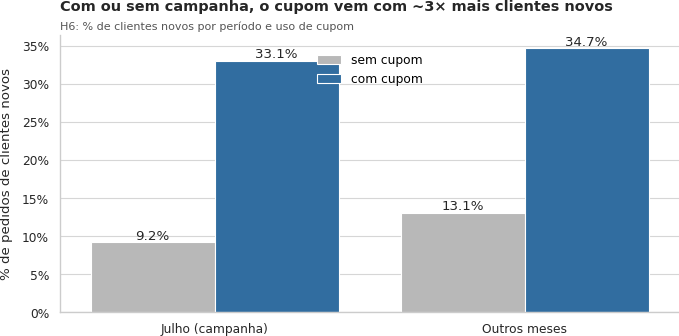

In [55]:
fig, ax = plt.subplots(figsize=(10, 4.5))
plot6 = estr_pct[["sem cupom", "com cupom"]].reset_index().melt(id_vars="periodo", var_name="grupo", value_name="pct_novo")
sns.barplot(data=plot6, x="periodo", y="pct_novo", hue="grupo", palette=[COR["neutro"], COR["destaque"]], ax=ax)
for cont in ax.containers: ax.bar_label(cont, fmt="%.1f%%")
ax.yaxis.set_major_formatter(fmt_pct); ax.set_xlabel(""); ax.set_ylabel("% de pedidos de clientes novos"); ax.legend(title="", frameon=False)
titulo(ax, "Com ou sem campanha, o cupom vem com ~3× mais clientes novos", "H6: % de clientes novos por período e uso de cupom")
limpa(ax); plt.show()

### Tarefa 9.7 — Tabela-resumo (resposta sim/não)

In [56]:
tabela_h = pd.DataFrame(resultados)
tabela_h["p_valor"] = tabela_h["p_valor"].map(fp)
tabela_h["estatistica"] = tabela_h["estatistica"].map(lambda x: num(x, 2))
tabela_h

,hipotese,teste,estatistica,p_valor,efeito,resposta
0,H1 chuva × tempo,Mann-Whitney,"9.908.765,00","< 0,001",+9 min na mediana,SIM
1,H2 cupom × valor,Mann-Whitney,"4.726.533,50","< 0,001","R$ -5,63 na mediana",SIM
2,H3 tempo × nota,Spearman,"-0,24","< 0,001","nota 4,49 (≤35) × 4,20 (>35)",SIM
3,H4 cozinha × valor,Kruskal-Wallis,"3.303,33","< 0,001","ε² = 0,41",SIM
4,H5 cidade × pagamento,qui-quadrado,"3,86","0,695","V = 0,02",NÃO
5,H6 cupom × cliente novo fora de julho (minha),qui-quadrado + Mantel-Haenszel,"358,03","< 0,001","34,7% × 13,1% (2,7×); OR ajustado 3,69",SIM


---
## Etapa 10 — Conclusões

### Tarefa 10.1 — Figura principal

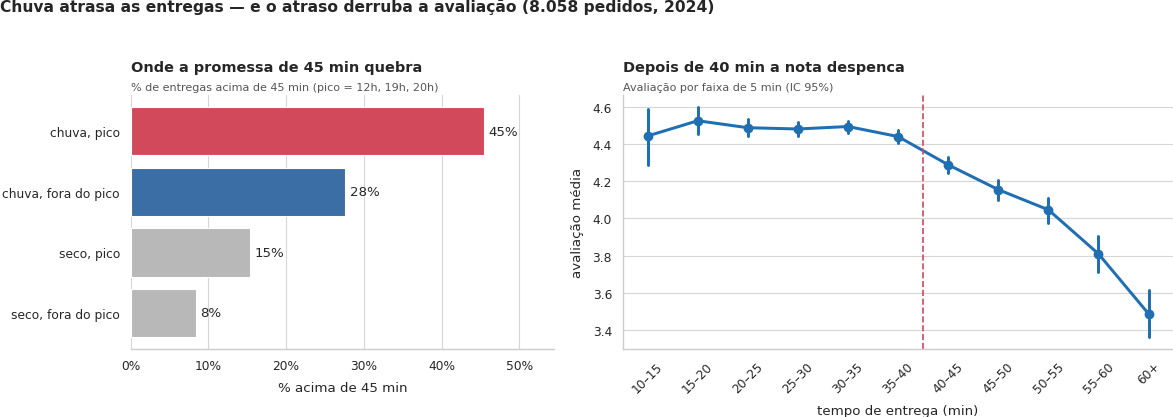

,% acima de 45 min
"seco, fora do pico",8.4
"seco, pico",15.3
"chuva, fora do pico",27.6
"chuva, pico",45.4


In [57]:
cen = df.dropna(subset=["tempo_entrega_min"]).assign(atraso=lambda x: x["tempo_entrega_min"] > 45)
HORAS_PICO = pivo.sum(axis=1).nlargest(3).index.tolist()
pico = cen["hora"].isin(HORAS_PICO)
cenarios = pd.Series({"seco, fora do pico": cen.loc[~cen.chuva & ~pico, "atraso"].mean(),
                      "seco, pico": cen.loc[~cen.chuva & pico, "atraso"].mean(),
                      "chuva, fora do pico": cen.loc[cen.chuva & ~pico, "atraso"].mean(),
                      "chuva, pico": cen.loc[cen.chuva & pico, "atraso"].mean()}) * 100
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.3]})
bb = a1.barh(cenarios.index, cenarios.values, color=[COR["neutro"], COR["neutro"], COR["chuva"], COR["alerta"]])
a1.bar_label(bb, labels=[f"{x:.0f}%" for x in cenarios.values], padding=4)
a1.xaxis.set_major_formatter(fmt_pct); a1.set_xlabel("% acima de 45 min"); a1.set_xlim(0, cenarios.max()*1.2)
titulo(a1, "Onde a promessa de 45 min quebra", f"% de entregas acima de 45 min (pico = {', '.join(f'{h}h' for h in sorted(HORAS_PICO))})")
sns.pointplot(data=aval_faixa[aval_faixa["faixa_tempo"].isin(mf.index)], x="faixa_tempo", y="avaliacao", order=mf.index,
              errorbar=("ci", 95), color=COR["destaque"], ax=a2)
a2.axvline(pos - .5, color=COR["alerta"], ls="--"); a2.tick_params(axis="x", rotation=45)
a2.set_xlabel("tempo de entrega (min)"); a2.set_ylabel("avaliação média")
titulo(a2, f"Depois de {FAIXA_QUEDA.split('–')[0]} min a nota despenca", "Avaliação por faixa de 5 min (IC 95%)")
limpa(a1, "x"); limpa(a2)
fig.suptitle(f"Chuva atrasa as entregas — e o atraso derruba a avaliação ({num(len(df),0)} pedidos, 2024)",
             fontsize=14, fontweight="bold", x=.01, ha="left", y=1.04)
plt.tight_layout(); fig.savefig(SAIDAS / "figura_principal.png", dpi=150, bbox_inches="tight"); plt.show()
display(cenarios.round(1).to_frame("% acima de 45 min"))

### Tarefa 10.2 — Cinco achados

In [58]:
achados = [
    f"**Chuva atrasa as entregas em {num(ef_min,0)} min (mediana).** Com chuva, {pct((com > 45).mean())} passam de 45 min, contra "
    f"{pct((sem > 45).mean())} sem chuva; no pior cenário ({cenarios.idxmax()}) chega a {num(cenarios.max(),0)}% (Tarefas 6.8, 9.1 e 10.1).",
    f"**Demora derruba a avaliação:** até 35 min a nota média é {num(rap.mean(),2)}; acima, {num(dem.mean(),2)} (ρ = {num(rho,2)}, Tarefa 9.3). "
    f"A queda forte começa na faixa de {FAIXA_QUEDA} min (Tarefa 7.7).",
    f"**{pct(acima45)} das entregas quebrariam uma promessa de 45 min** ({num((t > 45).sum(),0)} pedidos; 90% chegam em até {num(perc[.9],0)} min, Tarefa 5.4).",
    f"**O cupom traz cliente novo o ano inteiro (H6 = SIM):** fora de julho, {pct(pn6[True])} dos pedidos com cupom são de clientes novos, "
    f"contra {pct(pn6[False])} sem cupom — {num(razao6)}× (p {fp(p6_uni)}; OR ajustado pela campanha {num(or_mh,1)}). No Julho de cupons o uso foi "
    f"{num(jul['taxa_cupom_%'],0)}% (outros meses {num(resto['taxa_cupom_%'],0)}%) e os pedidos/dia variaram {num(var_jul)}% (Tarefas 6.7 e 9.6).",
    f"**O pedido típico é {brl(df['valor_pedido'].median(),0)} e depende da cozinha:** de {brl(med_c.iloc[0],0)} ({med_c.index[0]}) a "
    f"{brl(med_c.iloc[-1],0)} ({med_c.index[-1]}), ε² = {num(eps2,2)}; {len(grandes)} pedidos corporativos puxam a média para "
    f"{brl(df['valor_pedido'].mean(),0)} (Tarefas 4.5 e 9.4).",
]
display(Markdown("\n".join(f"{i}. {a}" for i, a in enumerate(achados, 1))))

1. **Chuva atrasa as entregas em 9 min (mediana).** Com chuva, 35,3% passam de 45 min, contra 11,3% sem chuva; no pior cenário (chuva, pico) chega a 45% (Tarefas 6.8, 9.1 e 10.1).
2. **Demora derruba a avaliação:** até 35 min a nota média é 4,49; acima, 4,20 (ρ = -0,24, Tarefa 9.3). A queda forte começa na faixa de 40–45 min (Tarefa 7.7).
3. **18,4% das entregas quebrariam uma promessa de 45 min** (1.476 pedidos; 90% chegam em até 50 min, Tarefa 5.4).
4. **O cupom traz cliente novo o ano inteiro (H6 = SIM):** fora de julho, 34,7% dos pedidos com cupom são de clientes novos, contra 13,1% sem cupom — 2,7× (p < 0,001; OR ajustado pela campanha 3,7). No Julho de cupons o uso foi 46% (outros meses 18%) e os pedidos/dia variaram 22,9% (Tarefas 6.7 e 9.6).
5. **O pedido típico é R$ 62 e depende da cozinha:** de R$ 38 (Doces) a R$ 108 (Japonesa), ε² = 0,41; 24 pedidos corporativos puxam a média para R$ 72 (Tarefas 4.5 e 9.4).

### Tarefa 10.3 — Três recomendações

In [59]:
recomendacoes = [
    ("Plano de chuva: mais entregadores e prazo maior exibido nos dias com previsão de chuva.", "1, 3",
     "% acima de 45 min em dias de chuva"),
    (f"Meta de entrega em até {FAIXA_QUEDA.split('–')[0]} min, com alerta para restaurantes e regiões que passam disso.", "2, 3",
     "avaliação média e % de notas abaixo de 4"),
    ("Cupom como porta de entrada o ano todo (primeiro pedido), medido com teste A/B antes de repetir o Julho de cupons.", "4",
     "% de clientes novos e custo do cupom por cliente novo"),
]
display(pd.DataFrame(recomendacoes, columns=["recomendação", "achados", "métrica"]))

,recomendação,achados,métrica
0,Plano de chuva: mais entregadores e prazo maior exibido nos dias com previsão de chuva.,"1, 3",% acima de 45 min em dias de chuva
1,"Meta de entrega em até 40 min, com alerta para restaurantes e regiões que passam disso.","2, 3",avaliação média e % de notas abaixo de 4
2,"Cupom como porta de entrada o ano todo (primeiro pedido), medido com teste A/B antes de repetir o Julho de cupons.",4,% de clientes novos e custo do cupom por cliente novo


### Tarefa 10.4 — Limitações
1. **Sem `cliente_id`:** não dá para medir recompra nem se o cliente do cupom voltou.
2. **Sem custo do cupom e margem:** não sabemos se o cupom se paga.
3. **Dados observacionais:** associações, não prova de causa (ex.: o app pode dar cupom justamente a quem é novo).
4. **Um ano e 3 cidades:** sem comparação com outro ano.
5. **Avaliação opcional:** quem avalia pode não representar todos.

---
## Etapa 11 — Publicação

### Tarefa 11.1 — Base limpa e dicionário

In [60]:
limpo = df.drop(columns=[c for c in df.columns if c.startswith("_")] + ["faixa_tempo", "periodo"], errors="ignore")
limpo.to_csv(SAIDAS / "delivery_pedidos_limpo.csv", index=False)
DESC = {"pedido_id": "identificador do pedido", "data_hora": "data e hora do pedido", "cidade": "cidade padronizada (3 valores)",
        "bairro": "bairro de entrega", "restaurante_id": "identificador do restaurante", "tipo_cozinha": "tipo de cozinha",
        "plataforma": "Android, iOS, Web ou Não informada", "forma_pagamento": "forma padronizada (4 valores)",
        "cupom": "usou cupom", "cliente_novo": "primeiro pedido do cliente", "chuva": "choveu na cidade no dia",
        "distancia_km": "distância restaurante → cliente", "tempo_entrega_min": "minutos até a entrega",
        "valor_pedido": "valor dos itens em R$ (sem taxa)", "taxa_entrega": "taxa de entrega em R$", "avaliacao": "nota 1 a 5 (opcional)",
        "data": "dia do pedido", "mes": "mês (1–12)", "hora": "hora (0–23)", "dia_semana": "Seg…Dom",
        "tempo_invalido": "True = tempo era 999 ou negativo (virou NaN)",
        "distancia_invalida": f"True = distância > {num(LIMITE_KM,0)} km (virou NaN)",
        "pedido_grande": f"True = valor ≥ {num(CORTE,0)}× a mediana da cozinha (mantido)"}
dicionario = pd.DataFrame({"coluna": limpo.columns, "tipo": limpo.dtypes.astype(str).values,
                           "exemplo": [str(limpo[c].dropna().iloc[0]) for c in limpo.columns],
                           "% faltantes": (limpo.isna().mean()*100).round(2).values,
                           "descrição": [DESC.get(c, "") for c in limpo.columns]})
dicionario.to_csv(SAIDAS / "dicionario_dados.csv", index=False)
print("Salvo em saidas/:", limpo.shape)
dicionario

Salvo em saidas/: (8058, 23)


,coluna,tipo,exemplo,% faltantes,descrição
0,pedido_id,object,500000,0.00,identificador do pedido
1,data_hora,datetime64[ns],2024-01-01 11:21:00,0.00,data e hora do pedido
2,cidade,object,São Paulo,0.00,cidade padronizada (3 valores)
3,bairro,object,Tatuapé,0.00,bairro de entrega
4,restaurante_id,object,R912,0.00,identificador do restaurante
5,tipo_cozinha,object,Hambúrguer,0.00,tipo de cozinha
6,plataforma,object,Android,0.00,"Android, iOS, Web ou Não informada"
7,forma_pagamento,object,Pix,0.00,forma padronizada (4 valores)
8,cupom,bool,False,0.00,usou cupom
9,cliente_novo,bool,False,0.00,primeiro pedido do cliente


### Tarefa 11.2 — README (gerado pelo código)

In [61]:
hip = "\n".join(f"| {x['hipotese']} | {x['teste']} | {x['p_valor']} | {x['efeito']} | **{x['resposta']}** |" for _, x in tabela_h.iterrows())
rec = "\n".join(f"| {i} | {a_} | {b_} | {c_} |" for i, (a_, b_, c_) in enumerate(recomendacoes, 1))
ach = "\n".join(f"- {a_}" for a_ in achados)
dic = "\n".join(f"| {r.coluna} | {r.tipo} | {r.exemplo} | {r._4} | {r.descrição} |" for r in dicionario.itertuples())
readme = f"""# Chuva atrasa as entregas e o atraso derruba a avaliação — diagnóstico 2024 do app de delivery

Em 2024, {pct(acima45)} das entregas passaram de 45 min; com chuva a entrega típica leva {num(ef_min,0)} min a mais e, depois de {FAIXA_QUEDA.split('–')[0]} min, a avaliação despenca. O cupom está associado a ~{num(razao6,0)}× mais clientes novos, mesmo fora da campanha de julho.

![Figura principal](saidas/figura_principal.png)

## 1. Pergunta de negócio
A diretoria pediu um diagnóstico de 2024 em três frentes: **operação** (quando os pedidos acontecem e o que atrasa a entrega), **clientes** (quanto gastam e o que derruba a avaliação) e **alavancas** (cupons e chuva).

## 2. Dados
- **Fonte:** `dados/delivery_pedidos.csv`, base fornecida no módulo DS-PY-018 (CAIXAVERSO / Ada Tech).
- **Período:** {inicio:%d/%m/%Y} a {fim:%d/%m/%Y} · São Paulo, Rio de Janeiro e Belo Horizonte.
- **Tamanho:** {bruto.shape[0]} × {bruto.shape[1]} (original) → {limpo.shape[0]} × {limpo.shape[1]} (limpa). Nenhum pedido removido.
- **Unidade de observação:** um pedido.

### Dicionário da base limpa (`saidas/delivery_pedidos_limpo.csv`)
| Coluna | Tipo | Exemplo | % faltantes | Descrição |
|---|---|---|---|---|
{dic}

## 3. Como rodar
Pré-requisitos: **Python 3.10 ou superior** e **Git** instalados.

```bash
# 1. Baixar o projeto
git clone https://github.com/SEU-USUARIO/projeto-delivery-flaviane.git
cd projeto-delivery-flaviane

# 2. (opcional, recomendado) criar um ambiente virtual
python -m venv .venv
.venv\\Scripts\\activate          # Windows
# source .venv/bin/activate      # Linux / Mac

# 3. Instalar as bibliotecas
pip install -r requirements.txt

# 4. Abrir o notebook
jupyter notebook projeto_final.ipynb
```
- A base original já está em `dados/delivery_pedidos.csv` — **não precisa baixar nada à parte**.
- No Jupyter, use **Kernel → Restart & Run All**. No **VS Code**: abra a pasta do projeto, abra `projeto_final.ipynb`, escolha o kernel Python e clique em **Executar Tudo**.
- Ao final, a pasta `saidas/` é gerada de novo (base limpa, dicionário e figura principal).
- Tempo de execução: cerca de 1 minuto.

## 4. Estrutura do repositório
```
projeto-delivery-flaviane/
├── README.md                 ← este arquivo
├── requirements.txt          ← bibliotecas
├── projeto_final.ipynb       ← análise completa (Etapas 1 a 11), já executado
├── apresentacao_roteiro.md   ← roteiro da apresentação de 7 min
├── dados/
│   └── delivery_pedidos.csv  ← base original (não alterada)
└── saidas/
    ├── delivery_pedidos_limpo.csv
    ├── dicionario_dados.csv
    └── figura_principal.png
```

## 5. Metodologia e decisões de limpeza
- **{quebradas.sum()} linhas** vieram com o pedido inteiro numa só coluna (o valor "R$ 44,02" tinha vírgula) → re-lidas com o leitor de CSV e devolvidas às colunas. Nenhum pedido perdido.
- Cidade ({antes_cidade.nunique()} grafias → 3) e pagamento ({antes_pag.nunique()} grafias → 4) padronizados pelo texto normalizado.
- `valor_pedido` em texto com R$ convertido sem perda; `cupom`, `cliente_novo` e `chuva` viraram booleanos.
- Tempo 999/negativo e distâncias acima de {num(LIMITE_KM,0)} km → NaN com flag; **nenhuma linha removida**.
- {len(grandes)} pedidos corporativos mantidos com flag `pedido_grande`; ticket típico = **mediana**.
- Testes não paramétricos (Mann-Whitney, Kruskal-Wallis, Spearman) porque as variáveis são assimétricas; sempre com tamanho de efeito.

## 6. Hipóteses (α = 5%) — resposta sim/não
| Hipótese | Teste | p-valor | Efeito | Resposta |
|---|---|---|---|---|
{hip}

**H6 (criada por mim):** *o cupom continua trazendo mais clientes novos mesmo fora do Julho de cupons?* — controla a campanha, que é a variável confundidora.

## 7. Principais achados
{ach}

## 8. Recomendações
| # | Recomendação | Achados | Métrica para acompanhar |
|---|---|---|---|
{rec}

## 9. Limitações e próximos passos
- Sem `cliente_id`: não dá para medir recompra nem se o cliente do cupom voltou.
- Sem custo do cupom e margem: não sabemos se ele se paga.
- Dados observacionais: as relações são associações, não causa.
- Próximo passo: teste A/B de cupom e incluir o identificador do cliente.

## 10. Autora
**Flaviane Cristina Pereira Marra** · DS-PY-018 · CAIXAVERSO / Ada Tech · Turma 1735 · trabalho individual
"""
(RAIZ / "README.md").write_text(readme, encoding="utf-8")
display(Markdown("## Principais achados\n\n" + ach))

## Principais achados

- **Chuva atrasa as entregas em 9 min (mediana).** Com chuva, 35,3% passam de 45 min, contra 11,3% sem chuva; no pior cenário (chuva, pico) chega a 45% (Tarefas 6.8, 9.1 e 10.1).
- **Demora derruba a avaliação:** até 35 min a nota média é 4,49; acima, 4,20 (ρ = -0,24, Tarefa 9.3). A queda forte começa na faixa de 40–45 min (Tarefa 7.7).
- **18,4% das entregas quebrariam uma promessa de 45 min** (1.476 pedidos; 90% chegam em até 50 min, Tarefa 5.4).
- **O cupom traz cliente novo o ano inteiro (H6 = SIM):** fora de julho, 34,7% dos pedidos com cupom são de clientes novos, contra 13,1% sem cupom — 2,7× (p < 0,001; OR ajustado pela campanha 3,7). No Julho de cupons o uso foi 46% (outros meses 18%) e os pedidos/dia variaram 22,9% (Tarefas 6.7 e 9.6).
- **O pedido típico é R$ 62 e depende da cozinha:** de R$ 38 (Doces) a R$ 108 (Japonesa), ε² = 0,41; 24 pedidos corporativos puxam a média para R$ 72 (Tarefas 4.5 e 9.4).

### Roteiro da apresentação (7 minutos)

In [62]:
roteiro = f"""# Roteiro da apresentação — 7 minutos
**Flaviane Cristina Pereira Marra · Projeto final DS-PY-018**

## 0:00–0:50 · Abertura e contexto
"Analisei {num(len(df),0)} pedidos de 2024 em São Paulo, Rio e BH. Em uma frase: **a chuva atrasa as entregas, e o atraso derruba a avaliação.**"

## 0:50–1:30 · Hipóteses
"Das cinco hipóteses do roteiro, quatro deram SIM e a de pagamento por cidade deu NÃO. Eu criei uma sexta: **o cupom continua trazendo mais clientes novos mesmo fora do Julho de cupons?** A resposta foi SIM."

## 1:30–2:15 · Dificuldade encontrada
"{quebradas.sum()} pedidos vieram com a linha inteira numa coluna só, porque o valor estava escrito como 'R$ 44,02'. Re-li essas linhas e não perdi nenhum pedido. Também havia {antes_cidade.nunique()} grafias para 3 cidades, tempo com 999 e negativo e distâncias impossíveis. {len(grandes)} pedidos muito caros eram reais, de empresas; usei a mediana."

## 2:15–5:00 · Cinco achados
""" + "\n".join(f"{i}. {a_}" for i, a_ in enumerate(achados, 1)) + """

## 5:00–6:15 · Três recomendações
""" + "\n".join(f"{i}. **{a_}** Métrica: {c_}." for i, (a_, b_, c_) in enumerate(recomendacoes, 1)) + """

## 6:15–7:00 · Limitação e fechamento
"A base não identifica o cliente, então não sei se quem entrou com cupom voltou. E os dados mostram relação, não causa. O próximo passo é um teste A/B de cupom. Obrigada."
"""
(RAIZ / "apresentacao_roteiro.md").write_text(roteiro, encoding="utf-8")
display(Markdown(roteiro))

# Roteiro da apresentação — 7 minutos
**Flaviane Cristina Pereira Marra · Projeto final DS-PY-018**

## 0:00–0:50 · Abertura e contexto
"Analisei 8.058 pedidos de 2024 em São Paulo, Rio e BH. Em uma frase: **a chuva atrasa as entregas, e o atraso derruba a avaliação.**"

## 0:50–1:30 · Hipóteses
"Das cinco hipóteses do roteiro, quatro deram SIM e a de pagamento por cidade deu NÃO. Eu criei uma sexta: **o cupom continua trazendo mais clientes novos mesmo fora do Julho de cupons?** A resposta foi SIM."

## 1:30–2:15 · Dificuldade encontrada
"720 pedidos vieram com a linha inteira numa coluna só, porque o valor estava escrito como 'R$ 44,02'. Re-li essas linhas e não perdi nenhum pedido. Também havia 13 grafias para 3 cidades, tempo com 999 e negativo e distâncias impossíveis. 24 pedidos muito caros eram reais, de empresas; usei a mediana."

## 2:15–5:00 · Cinco achados
1. **Chuva atrasa as entregas em 9 min (mediana).** Com chuva, 35,3% passam de 45 min, contra 11,3% sem chuva; no pior cenário (chuva, pico) chega a 45% (Tarefas 6.8, 9.1 e 10.1).
2. **Demora derruba a avaliação:** até 35 min a nota média é 4,49; acima, 4,20 (ρ = -0,24, Tarefa 9.3). A queda forte começa na faixa de 40–45 min (Tarefa 7.7).
3. **18,4% das entregas quebrariam uma promessa de 45 min** (1.476 pedidos; 90% chegam em até 50 min, Tarefa 5.4).
4. **O cupom traz cliente novo o ano inteiro (H6 = SIM):** fora de julho, 34,7% dos pedidos com cupom são de clientes novos, contra 13,1% sem cupom — 2,7× (p < 0,001; OR ajustado pela campanha 3,7). No Julho de cupons o uso foi 46% (outros meses 18%) e os pedidos/dia variaram 22,9% (Tarefas 6.7 e 9.6).
5. **O pedido típico é R$ 62 e depende da cozinha:** de R$ 38 (Doces) a R$ 108 (Japonesa), ε² = 0,41; 24 pedidos corporativos puxam a média para R$ 72 (Tarefas 4.5 e 9.4).

## 5:00–6:15 · Três recomendações
1. **Plano de chuva: mais entregadores e prazo maior exibido nos dias com previsão de chuva.** Métrica: % acima de 45 min em dias de chuva.
2. **Meta de entrega em até 40 min, com alerta para restaurantes e regiões que passam disso.** Métrica: avaliação média e % de notas abaixo de 4.
3. **Cupom como porta de entrada o ano todo (primeiro pedido), medido com teste A/B antes de repetir o Julho de cupons.** Métrica: % de clientes novos e custo do cupom por cliente novo.

## 6:15–7:00 · Limitação e fechamento
"A base não identifica o cliente, então não sei se quem entrou com cupom voltou. E os dados mostram relação, não causa. O próximo passo é um teste A/B de cupom. Obrigada."


### Tarefa 11.3 — Checklist de publicação
- [x] Repositório **público** com notebook, `README.md`, `requirements.txt`, `dados/` e `saidas/`.
- [x] `README.md` mostra a figura principal e explica **como rodar** (item 3).
- [x] CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [x] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [x] Nenhum gráfico sem título, rótulos e unidade.